In [1]:
%pip install -q "stable-baselines3>=2.0" "sb3-contrib>=2.0" gymnasium pillow imageio imageio-ffmpeg pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import io, json, re, hashlib, zipfile, warnings
from pathlib import Path
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sb3_contrib import MaskablePPO

# Archivos originales suministrados
ZIP_MODELO_1 = Path("modelos_Azul_3.zip")
ZIP_MODELOS_2_3 = Path("modelos distintos.zip")

BASE_SALIDAS = Path("salidas_sin_entrenamiento")
BASE_SALIDAS.mkdir(exist_ok=True, parents=True)
BASE_EXTRAIDOS = BASE_SALIDAS / "modelos_extraidos"

# Cada pareja juega esta cantidad de partidas, alternando asiento.
PARTIDAS_MATRIZ = 30             # 100+ = estimaciones más estables, pero más lento
PARTIDAS_VS_UNIFORME = 60
PARTIDAS_CRUCE_CAMPEONES = 120  # Encuentros de campeones de distintos grupos
SEMILLA_MATRIZ = 510000
SEMILLA_UNIFORME = 610000
SEMILLA_CRUCES = 710000
MAX_TURNOS = 300
UMBRAL_REFERENCIA = 70
UMBRALES_CADENAS = [60, 65, 70, 75, 80]
MAX_ESTADOS_CADENA = 500_000

PALETA = {
    "azul": "#327CB8", "oscuro": "#17466B",
    "medio": "#6AAEDF", "claro": "#BBDCF2", "fondo": "#EEF6FC"
}

print("Evaluación solamente: no se ejecutará ningún entrenamiento.")

Evaluación solamente: no se ejecutará ningún entrenamiento.


In [ ]:
# @title
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches

class Azul:

  def __init__(self, tableros, bolsas, centro, moda, descuento, ronda, Ficha_blanca):
    self.tableros = tableros
    self.bolsas = bolsas
    self.centro = centro
    self.moda = moda
    self.descuento = descuento #no estoy seguro si DCS o DC5 en la imagen y eso signifique descuento
    # self.puntaje = puntaje ######este segun yo no es necesario ahora al crear la clase jugador#######
    self.ronda =  ronda
    self.Ficha_blanca = Ficha_blanca
    # Reserva física: 20 fichas de cada uno de los 5 colores.
    # Se consume al preparar cada ronda; no se repone entre rondas.
    self.bolsa_grande = [color for color in range(1, 6) for _ in range(20)]
    self.repartidas_por_color = {color: 0 for color in range(1, 6)}
    self.historial_repartos = []

  def Sacar_fichas(self,ficha,n_bolsa): ######### puedes implementar que mueva las fichas al centro tambien a la hora de sacarlas de la bolsa#########
    if ficha in self.bolsas[n_bolsa]:
      cantidad_sacada = self.bolsas[n_bolsa].count(ficha)
      sobrante = [f for f in self.bolsas[n_bolsa] if f != ficha]
      self.centro.extend(sobrante)
      self.bolsas[n_bolsa] = [0,0,0,0]
      # self.bolsas[n_bolsa][self.bolsas[n_bolsa] == ficha] = 0
      # self.centro.extend(self.bolsas[n_bolsa])
      # self.bolsas[n_bolsa][self.bolsas[n_bolsa] != 0] = 0
      # self.centro = [x for x in self.centro if x != 0]
      return cantidad_sacada
    else:
      return 'No esta la ficha'

  def Poner_ficha_tablero(self,ficha,cantidad, fila,n_jugador):
    linea = self.tableros[n_jugador]['lineas_patron'][fila]
    if np.all((linea == 0) | (linea == ficha)): #np.unique(self.tableros[n_jugador]['lineas_patron'][fila]) == np.array([0]) or np.unique(self.tableros[n_jugador]['lineas_patron'][fila]) == np.array([0,ficha]):
      n,c = np.unique(linea, return_counts=True) #np.unique(self.tableros[n_jugador]['lineas_patron'][fila],return_counts=True)
      d = dict(zip(n,c))
      if 0 in d:
        sobrantes = cantidad - d[0]
        if sobrantes > 0:
          if ficha in d:
            for i in range(0,min(d[0],cantidad)):
              linea[i+d[ficha]] = ficha
            return sobrantes
          else:
            for i in range(0,min(d[0],cantidad)):
              linea[i] = ficha
            return sobrantes
        else:
          if ficha in d:
            for i in range(0,min(d[0],cantidad)):
              linea[i+d[ficha]] = ficha
            return 0
          else:
            for i in range(0,min(d[0],cantidad)):
              linea[i] = ficha
            return 0
      else:
        return cantidad
    else:
      return 'falla'



  def Sacar_ficha_centro(self,ficha): #####puedes hacer que retorne la cantidad para el tema de colocarlo en el tablero?#########
    if ficha in self.centro:
      cantidad_sacada = self.centro.count(ficha)
      #self.centro[self.centro == ficha] = 0
      #self.centro = [x for x in self.centro if x != 0]
      self.centro = [x for x in self.centro if x != ficha]
      return cantidad_sacada
    else:
      return 'No esta la ficha'


  def Poner_ficha_muralla(self, ficha,n_jugador, n_tablero, fila):

      muro = self.tableros[n_jugador][n_tablero][1]
      patron_base = [1, 2, 3, 4, 5]
      columna = (patron_base.index(ficha) + fila) % 5
      if muro[fila][columna] != 0:
          return "Error: Ya hay una ficha en esa posición del muro."

      muro[fila][columna] = ficha
      puntos = 1
      c = columna - 1
      while c >= 0 and muro[fila][c] != 0:
          puntos += 1
          c -= 1

      c = columna + 1
      while c < 5 and muro[fila][c] != 0:
          puntos += 1
          c += 1

      f = fila - 1
      while f >= 0 and muro[f][columna] != 0:
          puntos += 1
          f -= 1

      f = fila + 1
      while f < 5 and muro[f][columna] != 0:
          puntos += 1
          f += 1

      return puntos







def crear_azul(num_jugadores=2):
    """Cada llamada crea una partida NUEVA, con tableros independientes."""
    bolsas = [[0, 0, 0, 0] for _ in range(5)]  # Se llenan en preparar_ronda()
    centro = []
    moda = np.zeros(5, dtype=int)
    tableros = []
    for _ in range(num_jugadores):
        tableros.append({
            'lineas_patron': [np.zeros(i, dtype=int) for i in range(1, 6)],
            'muro': np.zeros((5, 5), dtype=int)
        })
    descuento = [np.zeros(7, dtype=int) for _ in range(num_jugadores)]
    return Azul(tableros, bolsas, centro, moda, descuento, 1, True)


class Jugador:
    def __init__(self, nombre):
        self.nombre = nombre
        self.puntos = 0

    def sumar_puntos(self, cantidad):
        self.puntos += cantidad



class Partida:
  def __init__(self, azul, seed=None):
    self.filas_puntuadas = set()
    self.azul = azul
    self.jugadores = [Jugador("Jugador 1"), Jugador("Jugador 2")]
    self.turno = 0
    self.rng = np.random.default_rng(seed)
    self.azul.moda = self.rng.permutation(np.arange(1, 6))
    self.descuentos_ronda = [0, 0]
    self.sobrantes_ronda = [0, 0]
    self.terminada = False
    self.azul.ronda = 1
    self.preparar_ronda()

  def siguiente_turno(self):
    self.turno = (self.turno + 1) % 2

  def realizar_jugada(self, bolsa, ficha, fila):
      if not 1 <= ficha <= 5:
        print("Color inválido.")
        return False

      if not 0 <= bolsa <= len(self.azul.bolsas):
        print("Bolsa inválida.")
        return False

      if bolsa == 0: #vemos si hay fichas del color
        disponibles = np.asarray(self.azul.centro)
      else:
        disponibles = np.asarray(self.azul.bolsas[bolsa - 1])

      if not np.any(disponibles == ficha):
        print("No hay fichas de ese color.")
        return False

      tablero = self.azul.tableros[self.turno]['lineas_patron']

      if not 0 <= fila <= len(tablero):
        print("Fila inválida.")
        return False

      if fila != 0: #vemos si la fila permite el color
        casillas = tablero[fila - 1]
        if not np.any(casillas == 0):
          print("La fila está completa. Elige otra fila o la fila 0 para descartar.")
          return False
        if np.any((casillas != 0) & (casillas != ficha)):
          print("La fila contiene otro color.")
          return False

      # Sacar fichas del centro o de una fábrica
      if bolsa == 0:
        cantidad = self.azul.Sacar_ficha_centro(ficha)

        if self.azul.Ficha_blanca:
          self.azul.Ficha_blanca = False
          self.dueno_ficha_blanca = self.turno
          self.descuentos_ronda[self.turno] += 1
          print("Tomaste la ficha blanca: -1 punto.")

      else:
        cantidad = self.azul.Sacar_fichas(ficha, bolsa - 1)

      if fila == 0: #colocar las fichas y contar restantes
        sobrantes = cantidad
      else:
        sobrantes = self.azul.Poner_ficha_tablero(ficha, cantidad, fila - 1, self.turno )

      # descuentos
      penalizaciones = [1, 1, 2, 2, 3, 3]
      inicio = self.sobrantes_ronda[self.turno]
      fin = min(inicio + sobrantes, len(penalizaciones))
      descuento = sum(penalizaciones[inicio:fin])

      self.descuentos_ronda[self.turno] += descuento
      self.sobrantes_ronda[self.turno] += sobrantes

      print("Fichas tomadas:", cantidad)
      print("Fichas sobrantes:", sobrantes)

      return True


  def quedan_fichas(self):
    return (any(np.any(np.asarray(bolsa) != 0) for bolsa in self.azul.bolsas)
            or np.any(np.asarray(self.azul.centro) != 0))

  def jugadas_posibles(self):
    """Tuplas (bolsa, color, fila), donde fila 0 significa descarte."""
    opciones = []
    fuentes = [(0, self.azul.centro)] + [
        (i + 1, bolsa) for i, bolsa in enumerate(self.azul.bolsas)
    ]
    tablero = self.azul.tableros[self.turno]['lineas_patron']
    for n_bolsa, fichas in fuentes:
      fichas = np.asarray(fichas)
      colores = np.unique(fichas[(fichas >= 1) & (fichas <= 5)])
      for color in colores:
        color = int(color)
        opciones.append((n_bolsa, color, 0))  # Descartar todo el color elegido.
        for i, fila in enumerate(tablero, start=1):
          if np.any(fila == 0) and np.all((fila == 0) | (fila == color)):
            opciones.append((n_bolsa, color, i))
    return opciones

  def jugar_turno(self, jugada, mostrar=False):
    """Recibe (bolsa, color, fila). No pide datos por consola."""
    if self.terminada:
      print("La partida ya terminó.")
      return False

    if not isinstance(jugada, (tuple, list)) or len(jugada) != 3:
      raise ValueError("La jugada debe ser una tupla (bolsa, ficha, fila).")
    if not all(isinstance(valor, (int, np.integer)) for valor in jugada):
      raise ValueError("Bolsa, ficha y fila deben ser números enteros.")

    if mostrar:
      self.mostrar_estado()

    bolsa, ficha, fila = (int(v) for v in jugada)
    print(f"\nTurno de {self.jugadores[self.turno].nombre}: {(bolsa, ficha, fila)}")
    if not self.realizar_jugada(bolsa, ficha, fila):
      return False

    self.siguiente_turno()
    if not self.quedan_fichas():
      self.finalizar_ronda()
      if self.azul.ronda < 5:
        self.azul.ronda += 1
        self.preparar_ronda()
      else:
        self.terminada = True
        self.mostrar_resultado_final()
    return True

  def jugar_ronda(self, jugadas, mostrar=False):
    """Recibe una secuencia de jugadas. Se detiene al acabar la ronda."""
    ronda_actual = self.azul.ronda
    for jugada in jugadas:
      if self.terminada or self.azul.ronda != ronda_actual:
        break
      self.jugar_turno(jugada, mostrar=mostrar)
    return self.estado()

  def jugar(self, jugadas, mostrar=False):
    """Acepta una sola jugada (bolsa, ficha, fila) o una lista de jugadas."""
    if (isinstance(jugadas, (tuple, list)) and len(jugadas) == 3
        and all(isinstance(x, (int, np.integer)) for x in jugadas)):
      return self.jugar_turno(jugadas, mostrar=mostrar)
    for jugada in jugadas:
      if self.terminada:
        break
      self.jugar_turno(jugada, mostrar=mostrar)
    return self.estado()

  def estado(self):
    return {
      'ronda': self.azul.ronda,
      'turno': self.turno,
      'puntos': [j.puntos for j in self.jugadores],
      'terminada': self.terminada,
    }

  def estado_reserva(self):
    """Estado de las fichas extraídas y las que quedan disponibles."""
    return {
      'ronda_actual': self.azul.ronda,
      'restantes_total': len(self.azul.bolsa_grande),
      'restantes_por_color': {
        color: self.azul.bolsa_grande.count(color) for color in range(1, 6)
      },
      'repartidas_por_color': self.azul.repartidas_por_color.copy(),
      'historial_repartos': [
        {
          'ronda': registro['ronda'],
          'bolsas': [bolsa.copy() for bolsa in registro['bolsas']],
          'por_color': registro['por_color'].copy(),
        }
        for registro in self.azul.historial_repartos
      ],
    }

  def mostrar_resultado_final(self):
    print("\n========== FIN DE PARTIDA ==========")
    puntos = [jugador.puntos for jugador in self.jugadores]
    for jugador in self.jugadores:
      print(jugador.nombre, ":", jugador.puntos)
    if puntos[0] == puntos[1]:
      print("\nEmpate")
    else:
      ganador = self.jugadores[int(np.argmax(puntos))]
      print(f"\nGanador: {ganador.nombre} con {ganador.puntos} puntos.")

  def finalizar_ronda(self):
    moda = int(self.azul.moda[self.azul.ronda - 1])
    print(f"\nResultados de la ronda {self.azul.ronda}")
    print("Moda:", moda)
    for j, jugador in enumerate(self.jugadores):
      puntos_filas = 0
      puntos_moda =0
      for fila in self.azul.tableros[j]['lineas_patron']:
        puntos_moda += np.count_nonzero(fila == moda) # contar fichas de moda
        if np.all(fila != 0): #si la fila esta completa
          puntos_filas += len(fila)
          fila[:] = 0 #vaciar las compleras

      descuento = self.descuentos_ronda[j]
      puntos_ronda = puntos_filas + puntos_moda - descuento
      jugador.sumar_puntos(puntos_ronda)
      print(f"\n{jugador.nombre}")
      print("Puntos por filas:", puntos_filas)
      print("Puntos por moda:", puntos_moda)
      print("Descuentos:", descuento)
      print("Puntos de la ronda:", puntos_ronda)
      print("Total acumulado:", jugador.puntos)
    self.azul.puntaje = np.array([jugador.puntos for jugador in self.jugadores])

  def preparar_ronda(self):
    self.dueno_ficha_blanca = None
    self.sobrantes_ronda = [0, 0]
    # Extraer fichas SIN reposición de la misma reserva durante las 5 rondas.
    fichas_por_fabrica = 4
    total_a_extraer = len(self.azul.bolsas) * fichas_por_fabrica
    if len(self.azul.bolsa_grande) < total_a_extraer:
      raise ValueError("No hay suficientes fichas en la reserva para esta ronda.")

    self.rng.shuffle(self.azul.bolsa_grande)
    extraidas = [self.azul.bolsa_grande.pop() for _ in range(total_a_extraer)]
    for i in range(len(self.azul.bolsas)):
      inicio = i * fichas_por_fabrica
      self.azul.bolsas[i] = extraidas[inicio:inicio + fichas_por_fabrica]

    conteo_ronda = {color: extraidas.count(color) for color in range(1, 6)}
    for color, cantidad in conteo_ronda.items():
      self.azul.repartidas_por_color[color] += cantidad
    self.azul.historial_repartos.append({
      'ronda': self.azul.ronda,
      'bolsas': [bolsa.copy() for bolsa in self.azul.bolsas],
      'por_color': conteo_ronda.copy(),
    })
    # self.azul.centro = np.array([], dtype=int) #vaciar el centro
    self.azul.centro = []                       ####Lo mismo que las bolsas####
    self.azul.Ficha_blanca = True #restaurar la ficha blanca
    self.descuentos_ronda = [0, 0] #reiniciar los descuentos
    print(f"\n========== RONDA {self.azul.ronda} ==========")
    print("Moda de la ronda:", self.azul.moda[self.azul.ronda - 1])

  def mostrar_estado(self):
      """Muestra gráficamente el estado actual de la partida."""

      fig, ax = plt.subplots(figsize=(14, 9))
      ax.axis('off')

      colores_map = {
          0: '#E0E0E0',
          1: '#1E90FF',
          2: '#FFD700',
          3: '#DC143C',
          4: '#2F4F4F',
          5: '#FAFAFA',
          99: '#FF8C00'
      }

      # --- ENCABEZADO ---
      ax.text(
          0.5, 0.96,
          f"RONDA {self.azul.ronda} — Turno de: {self.jugadores[self.turno].nombre}",
          ha='center', va='center',
          fontsize=16, fontweight='bold',
          transform=ax.transAxes
      )

      # --- MODA ACTUAL ---
      moda = int(self.azul.moda[self.azul.ronda - 1])

      ax.text(
          0.49, 0.915, "Moda actual:",
          fontsize=12, fontweight='bold',
          ha='right', va='center',
          transform=ax.transAxes
      )

      rect = patches.Rectangle(
          (0.51, 0.895), 0.04, 0.04,
          facecolor=colores_map[moda],
          edgecolor='black',
          linewidth=1.5,
          transform=ax.transAxes
      )
      ax.add_patch(rect)

      ax.text(
          0.53, 0.915, str(moda),
          ha='center', va='center',
          fontsize=11, fontweight='bold',
          color='white' if moda == 4 else 'black',
          transform=ax.transAxes
      )

      # --- FÁBRICAS ---
      ax.text(
          0.5, 0.86, "Bolsas:",
          fontsize=12, fontweight='bold',
          ha='center', transform=ax.transAxes
      )

      n_fabricas = len(self.azul.bolsas)
      separacion = 0.18
      inicio = 0.5 - ((n_fabricas - 1) * separacion) / 2

      for i, fabrica in enumerate(self.azul.bolsas):

          x_base = inicio + i * separacion

          ax.text(
              x_base, 0.82, f"Bolsa {i+1}",
              fontsize=10, ha='center',
              transform=ax.transAxes
          )

          for j, ficha in enumerate(fabrica):

              x_pos = x_base - len(fabrica) * 0.0175 + j * 0.035
              col = colores_map.get(int(ficha), '#FFFFFF')

              rect = patches.Rectangle(
                  (x_pos, 0.76), 0.03, 0.04,
                  facecolor=col, edgecolor='black',
                  transform=ax.transAxes
              )
              ax.add_patch(rect)

              if ficha != 0:
                  ax.text(
                      x_pos + 0.015, 0.78, str(ficha),
                      ha='center', va='center',
                      fontsize=8, fontweight='bold',
                      color='white' if ficha == 4 else 'black',
                      transform=ax.transAxes
                  )

      # --- CENTRO DE LA MESA ---
      ax.text(
          0.5, 0.70,
          f"Centro (Total: {len(self.azul.centro)}):",
          fontsize=12, fontweight='bold',
          ha='center', transform=ax.transAxes
      )

      center_tiles = self.azul.centro
      visibles = center_tiles[:16]

      for idx, ficha in enumerate(visibles):

          row_c = idx // 8
          col_c = idx % 8

          cantidad_fila = min(8, len(visibles) - row_c * 8)
          x_inicio = 0.5 - (cantidad_fila * 0.03) / 2

          x_c = x_inicio + col_c * 0.03
          y_c = 0.63 - row_c * 0.045

          col = colores_map.get(int(ficha), '#FFFFFF')

          rect = patches.Rectangle(
              (x_c, y_c), 0.025, 0.035,
              facecolor=col, edgecolor='black',
              transform=ax.transAxes
          )
          ax.add_patch(rect)

          texto_ficha = 'BF' if ficha == 99 else str(ficha)

          ax.text(
              x_c + 0.0125, y_c + 0.0175,
              texto_ficha if ficha != 0 else '',
              ha='center', va='center',
              fontsize=7, fontweight='bold',
              color='white' if ficha == 4 else 'black',
              transform=ax.transAxes
          )

      # --- FICHA DE PENALIZACIÓN DEL CENTRO ---
      if self.azul.Ficha_blanca:

          rect = patches.Rectangle(
              (0.43, 0.52), 0.035, 0.04,
              facecolor=colores_map[99],
              edgecolor='black',
              linewidth=1.5,
              transform=ax.transAxes
          )
          ax.add_patch(rect)

          ax.text(
              0.4475, 0.54, "-1",
              ha='center', va='center',
              fontsize=9, fontweight='bold',
              transform=ax.transAxes
          )

          ax.text(
              0.48, 0.54, "Ficha de penalización disponible",
              fontsize=10, va='center',
              transform=ax.transAxes
          )

      # --- TABLEROS DE LOS JUGADORES ---
      for j_idx, jugador in enumerate(self.jugadores):

          x_offset = 0.07 + j_idx * 0.48
          y_offset = 0.36

          # Información del jugador
          ax.text(
              x_offset, 0.48,
              f"{jugador.nombre} | Puntos Totales: {jugador.puntos}",
              fontsize=11, fontweight='bold',
              transform=ax.transAxes
          )

          ax.text(
              x_offset, 0.445,
              f"Penalización Ronda: {self.descuentos_ronda[j_idx]}",
              fontsize=10,
              transform=ax.transAxes
          )

          # --- FICHA -1 DEL JUGADOR ---
          if getattr(self, 'dueno_ficha_blanca', None) == j_idx:

              rect = patches.Rectangle(
                  (x_offset + 0.27, 0.40), 0.035, 0.035,
                  facecolor=colores_map[99],
                  edgecolor='black',
                  linewidth=1.5,
                  transform=ax.transAxes
              )
              ax.add_patch(rect)

              ax.text(
                  x_offset + 0.2875, 0.4175, "-1",
                  ha='center', va='center',
                  fontsize=9, fontweight='bold',
                  transform=ax.transAxes
              )

              ax.text(
                  x_offset + 0.31, 0.4175, "Centro",
                  fontsize=9, va='center',
                  transform=ax.transAxes
              )

          # --- LÍNEAS DE PATRÓN ---
          ax.text(
              x_offset, y_offset,
              "Líneas de Patrón:",
              fontsize=10,
              transform=ax.transAxes
          )

          tablero_lineas = self.azul.tableros[j_idx]['lineas_patron']

          for fila_idx, fila in enumerate(tablero_lineas):

              for col_idx, ficha in enumerate(fila):

                  x_pos = x_offset + col_idx * 0.045
                  y_pos = y_offset - 0.065 - fila_idx * 0.055

                  col = colores_map.get(int(ficha), '#FFFFFF')

                  rect = patches.Rectangle(
                      (x_pos, y_pos), 0.04, 0.04,
                      facecolor=col, edgecolor='black',
                      transform=ax.transAxes
                  )
                  ax.add_patch(rect)

                  if ficha != 0:
                      ax.text(
                          x_pos + 0.02, y_pos + 0.02,
                          str(ficha),
                          ha='center', va='center',
                          fontsize=8, fontweight='bold',
                          color='white' if ficha == 4 else 'black',
                          transform=ax.transAxes
                      )

      plt.tight_layout()
      plt.show()

class PartidaSolitaria(Partida):
  def __init__(self, azul):
    super().__init__(azul)
    self.jugadores[1].nombre = "Computador"

  def jugada_computador(self):
    opciones = self.jugadas_posibles()
    if not opciones:
      raise ValueError("No quedan jugadas válidas para el computador.")
    indice = self.rng.integers(len(opciones))
    return opciones[indice]

  def jugar_turno(self, jugada, mostrar=False):
    """Recibe una jugada HUMANA y luego hace jugar al computador."""
    if self.turno != 0:
      raise ValueError("Ahora no es el turno del jugador humano.")

    valido = super().jugar_turno(jugada, mostrar=mostrar)
    if not valido:
      return False

    # El computador puede comenzar la ronda siguiente si acabó la anterior.
    while not self.terminada and self.turno == 1:
      jugada_cpu = self.jugada_computador()
      super().jugar_turno(jugada_cpu, mostrar=mostrar)
    return True




In [ ]:

import io
from contextlib import redirect_stdout
import numpy as np

NUM_ACCIONES = 6 * 5 * 6
PENALIZACIONES = (1, 1, 2, 2, 3, 3)


def codificar(jugada):
    bolsa, color, fila = (int(x) for x in jugada)
    if not (0 <= bolsa <= 5 and 1 <= color <= 5 and 0 <= fila <= 5):
        raise ValueError(f'Jugada fuera de rango: {jugada}')
    return (bolsa * 5 + color - 1) * 6 + fila


def decodificar(accion):
    accion = int(accion)
    if not 0 <= accion < NUM_ACCIONES:
        raise ValueError(f'Acción inválida: {accion}')
    bolsa, resto = divmod(accion, 30)
    color_menos_1, fila = divmod(resto, 6)
    return (bolsa, color_menos_1 + 1, fila)


def jugadas_legales(partida):
    return partida.jugadas_posibles() if not partida.terminada else []


def mascara_acciones(partida):
    mascara = np.zeros(NUM_ACCIONES, dtype=bool)
    for jugada in jugadas_legales(partida):
        mascara[codificar(jugada)] = True
    return mascara


def jugada_uniforme(partida, rng):
    """Uniforme EXACTA sobre las tuplas legales (no sobre colores)."""
    opciones = jugadas_legales(partida)
    if not opciones:
        raise ValueError('No quedan jugadas posibles')
    return opciones[int(rng.integers(len(opciones)))]


def valor_heuristico(partida, jugada):
    """Preferencia: completar filas, aprovechar la moda, reducir descarte.
    Es una política fija, NO una red entrenada.
    """
    bolsa, color, fila = jugada
    disponibles = (partida.azul.centro if bolsa == 0
                    else partida.azul.bolsas[bolsa - 1])
    cantidad = disponibles.count(color)
    jugador = partida.turno
    moda = int(partida.azul.moda[partida.azul.ronda - 1])
    if fila == 0:
        colocadas, sobrantes, bono = 0, cantidad, -1.0
    else:
        linea = partida.azul.tableros[jugador]['lineas_patron'][fila-1]
        libres = int(np.count_nonzero(linea == 0))
        colocadas = min(cantidad, libres)
        sobrantes = cantidad-colocadas
        bono = 2.0 * len(linea) * (cantidad >= libres) + 0.4 * (len(linea) - libres)
    inicio = partida.sobrantes_ronda[jugador]
    penalidad = sum(PENALIZACIONES[inicio:min(inicio+sobrantes, len(PENALIZACIONES))])
    penalidad_centro = int(bolsa == 0 and partida.azul.Ficha_blanca)
    return (1.1*colocadas + 1.4*(color == moda)*colocadas
            + bono - 2.0*penalidad - 1.3*penalidad_centro)


def jugada_heuristica(partida, rng):
    opciones = jugadas_legales(partida)
    if not opciones:
        raise ValueError('No quedan jugadas posibles')
    valores = np.array([valor_heuristico(partida, j) for j in opciones])
    mejores = np.flatnonzero(np.isclose(valores, valores.max()))
    return opciones[int(rng.choice(mejores))]


def observacion(partida, jugador):
    """Información visible: ronda, color de moda, bolsas, centro, reserva,
    líneas, marcadores, puntos y descarte de ambos jugadores.
    No incluye los colores futuros en 'moda'.
    """
    az = partida.azul
    rival = 1 - jugador
    moda = int(az.moda[az.ronda-1])
    datos = [az.ronda/5.0]
    datos += [float(moda == c) for c in range(1, 6)]
    for fabrica in az.bolsas:
        datos.extend(fabrica.count(c)/4 for c in range(1, 6))
    datos.extend(az.centro.count(c)/20 for c in range(1, 6))
    datos.append(float(az.Ficha_blanca))
    datos.extend(az.bolsa_grande.count(c)/20 for c in range(1, 6))
    for j in (jugador, rival):
        for linea in az.tableros[j]['lineas_patron']:
            color = next((int(x) for x in linea if x != 0), 0)
            datos.extend((color/5, np.count_nonzero(linea)/len(linea)))
    datos.extend(partida.jugadores[j].puntos/100 for j in (jugador, rival))
    datos.extend(partida.descuentos_ronda[j]/20 for j in (jugador, rival))
    datos.extend(partida.sobrantes_ronda[j]/20 for j in (jugador, rival))
    return np.asarray(datos, dtype=np.float32)


def nueva_partida(semilla):
    # Silenciar la impresión automática del motor, útil en simulaciones.
    with redirect_stdout(io.StringIO()):
        return Partida(crear_azul(), seed=semilla)


def _jugar_sin_imprimir(partida, jugada):
    with redirect_stdout(io.StringIO()):
        ok = partida.jugar_turno(jugada)
    if not ok:
        raise RuntimeError(f'Fallo al ejecutar jugada legal: {jugada}')




In [ ]:
CONJUNTOS = {
    "modelo_1": {"nombre": "Modelo 1 — Azul 3", "carpeta": BASE_EXTRAIDOS / "modelo_1_azul3", "archivos": {}, "historial": None},
    "modelo_2": {"nombre": "Modelo 2 — 1 a 1", "carpeta": BASE_EXTRAIDOS / "modelo_2_1a1", "archivos": {}, "historial": None},
    "modelo_3": {"nombre": "Modelo 3 — Heurística", "carpeta": BASE_EXTRAIDOS / "modelo_3_heuristica", "archivos": {}, "historial": None},
}

#hecho con ia
def preparar_archivos():
    if not ZIP_MODELO_1.exists() or not ZIP_MODELOS_2_3.exists():
        faltan = [str(p) for p in [ZIP_MODELO_1, ZIP_MODELOS_2_3] if not p.exists()]
        raise FileNotFoundError("Faltan estos ZIP en la carpeta del notebook: " + ", ".join(faltan))

    for item in CONJUNTOS.values():
        item["carpeta"].mkdir(parents=True, exist_ok=True)
        item["archivos"] = {}
        item["historial"] = None

    for origen, tipo in [(ZIP_MODELO_1, "primero"), (ZIP_MODELOS_2_3, "segundo")]:
        with zipfile.ZipFile(origen) as z:
            for nombre_interno in z.namelist():
                ruta_interna = Path(nombre_interno)
                nombre_fichero = ruta_interna.name
                if not nombre_fichero:
                    continue
                if tipo == "primero":
                    grupo = "modelo_1"
                elif "modelo_1a1" in nombre_interno.replace(" ", "").lower() or "modelo_1a1" in nombre_interno.lower():
                    grupo = "modelo_2"
                elif "modelo_heuristica" in nombre_interno.lower():
                    grupo = "modelo_3"
                else:
                    continue
                item = CONJUNTOS[grupo]
                destino = item["carpeta"] / nombre_fichero
                if re.fullmatch(r"R\d+\.zip", nombre_fichero, flags=re.IGNORECASE):
                    raw = z.read(nombre_interno)
                    if not destino.exists() or destino.stat().st_size != len(raw):
                        destino.write_bytes(raw)
                    num = int(re.search(r"R(\d+)\.zip", nombre_fichero, flags=re.IGNORECASE).group(1))
                    item["archivos"][num] = destino
                elif tipo == "primero" and nombre_fichero == "resultados_generaciones.json":
                    item["historial"] = json.loads(z.read(nombre_interno).decode("utf-8"))

    for grupo, item in CONJUNTOS.items():
        item["archivos"] = dict(sorted(item["archivos"].items()))
        if not item["archivos"]:
            raise RuntimeError(f"No encontré modelos .zip para {item['nombre']}.")
        print(f"{item['nombre']}: {len(item['archivos'])} redes: "
              + ", ".join(f"R{n}" for n in item["archivos"]))
    return CONJUNTOS

preparar_archivos()
#fin hehco con ia

Modelo 1 — Azul 3: 20 redes: R1, R2, R3, R4, R5, R6, R7, R8, R9, R10, R11, R12, R13, R14, R15, R16, R17, R18, R19, R20
Modelo 2 — 1 a 1: 10 redes: R1, R2, R3, R4, R5, R6, R7, R8, R9, R10
Modelo 3 — Heurística: 9 redes: R1, R2, R3, R4, R5, R6, R7, R8, R9


{'modelo_1': {'nombre': 'Modelo 1 — Azul 3',
  'carpeta': WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3'),
  'archivos': {1: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R1.zip'),
   2: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R2.zip'),
   3: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R3.zip'),
   4: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R4.zip'),
   5: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R5.zip'),
   6: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R6.zip'),
   7: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R7.zip'),
   8: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R8.zip'),
   9: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos/modelo_1_azul3/R9.zip'),
   10: WindowsPath('salidas_sin_entrenamiento/modelos_extraidos

In [ ]:
#hecho con ia
MODELOS = {}
HUELLAS = {}
DIM_OBS = len(observacion(nueva_partida(0), 0))

for grupo, item in CONJUNTOS.items():
    MODELOS[grupo] = {}
    HUELLAS[grupo] = {}
    for numero, ruta in item["archivos"].items():
        red = MaskablePPO.load(str(ruta), device="cpu")
        if tuple(red.observation_space.shape) != (DIM_OBS,):
            raise ValueError(f"Observación incompatible en {grupo}/R{numero}: {red.observation_space.shape} vs {(DIM_OBS,)}")
        if red.action_space.n != NUM_ACCIONES:
            raise ValueError(f"Acciones incompatibles en {grupo}/R{numero}: {red.action_space.n} vs {NUM_ACCIONES}")
        MODELOS[grupo][numero] = red
        HUELLAS[grupo][numero] = hashlib.sha256(ruta.read_bytes()).hexdigest()[:16]
    print(f"Cargados {len(MODELOS[grupo])} modelos de {item['nombre']} (modo evaluación).")

print(f"Observación: {DIM_OBS} elementos; acciones: {NUM_ACCIONES}.")
#fin hecho con ia

Cargados 20 modelos de Modelo 1 — Azul 3 (modo evaluación).
Cargados 10 modelos de Modelo 2 — 1 a 1 (modo evaluación).
Cargados 9 modelos de Modelo 3 — Heurística (modo evaluación).
Observación: 68 elementos; acciones: 180.


In [ ]:
#hecho con ia
def salida_grupo(grupo):
    ruta = BASE_SALIDAS / grupo
    ruta.mkdir(exist_ok=True, parents=True)
    return ruta


def nombre_agente(grupo, numero):
    return f"{CONJUNTOS[grupo]['nombre']} / R{numero}"


def accion_modelo(modelo, partida, jugador):
    obs = observacion(partida, jugador)
    mask = mascara_acciones(partida)
    accion, _ = modelo.predict(obs, action_masks=mask, deterministic=True)
    j = tuple(decodificar(int(np.asarray(accion).item())))
    if j not in partida.jugadas_posibles():
        raise RuntimeError(f"Acción ilegal generada por el modelo: {j}")
    return j


def jugar_enfrentamiento(modelo_a, modelo_b=None, n=30, semilla=10000):
    """Modelo A vs B; si B=None, el segundo rival es uniforme.
    Los mismos parámetros producen las mismas partidas. Alterna el asiento de A.
    """
    gana_a = gana_b = empates = 0
    diferencias = []
    for k in range(int(n)):
        p = nueva_partida(int(semilla) + k)
        asiento_a = k % 2
        rng_uniforme = np.random.default_rng(int(semilla) + k + 1234567)
        turnos = 0
        while not p.terminada:
            j = int(p.turno)
            if j == asiento_a:
                jugada = accion_modelo(modelo_a, p, j)
            elif modelo_b is None:
                jugada = jugada_uniforme(p, rng_uniforme)
            else:
                jugada = accion_modelo(modelo_b, p, j)
            _jugar_sin_imprimir(p, jugada)
            turnos += 1
            if turnos > MAX_TURNOS:
                raise RuntimeError("Exceso de turnos en el duelo. Comprueba el motor del juego.")
        a = int(p.jugadores[asiento_a].puntos)
        b = int(p.jugadores[1 - asiento_a].puntos)
        gana_a += (a > b)
        gana_b += (b > a)
        empates += (a == b)
        diferencias.append(a - b)
    return {"partidas": int(n), "victorias_a": int(gana_a), "victorias_b": int(gana_b),
            "empates": int(empates), "winrate_a": gana_a/n, "winrate_b": gana_b/n,
            "diferencia_media": float(np.mean(diferencias))}


def leer_json(ruta):
    if not ruta.exists():
        return {}
    with ruta.open(encoding="utf8") as f:
        return json.load(f)


def guardar_json(ruta, datos):
    temporal = ruta.with_suffix(ruta.suffix + ".tmp")
    with temporal.open("w", encoding="utf8") as f:
        json.dump(datos, f, indent=2, ensure_ascii=False)
    temporal.replace(ruta)


def duelo_cache(archivo_cache, modelo_a, modelo_b, huella_a, huella_b,
               n, semilla, etiqueta_a, etiqueta_b):
    llave = f"{etiqueta_a}:{huella_a}__{etiqueta_b}:{huella_b}__n{n}__semilla{semilla}"
    cache = leer_json(archivo_cache)
    if llave in cache:
        return cache[llave]
    r = jugar_enfrentamiento(modelo_a, modelo_b, n=n, semilla=semilla)
    cache[llave] = r
    guardar_json(archivo_cache, cache)
    return r


def cadena_larga(M, ids, umbral, unif, max_estados=MAX_ESTADOS_CADENA):
    """Cadena de mejora: sucesor gana >= umbral a predecesor,
    ambos superan umbral vs uniforme. Nunca repite agentes.
    Exploración exacta salvo si se supera max_estados (se marca aproximada).
    """
    n = len(ids)
    validos = [i for i in range(n) if unif[i] >= umbral]
    if not validos:
        return [], True
    vecinos = {
        i: [j for j in validos if j != i and np.isfinite(M[j, i]) and M[j, i] >= umbral]
        for i in validos
    }
    for i in validos:
        vecinos[i].sort(key=lambda j: (-len(vecinos[j]) if j in vecinos else 0, j))
    mejor = []
    contador = 0
    exacto = True
    vistos = set()

    def explorar(actual, mascara, camino):
        nonlocal mejor, contador, exacto
        if len(camino) > len(mejor):
            mejor = camino.copy()
        if len(mejor) == len(validos):
            return
        if contador >= max_estados:
            exacto = False
            return
        estado = (actual, mascara)
        if estado in vistos:
            return
        vistos.add(estado)
        contador += 1
        # Una extensión no puede superar longitud de todos los candidatos.
        for siguiente in vecinos[actual]:
            if not mascara & (1 << siguiente):
                explorar(siguiente, mascara | (1 << siguiente), camino + [siguiente])
                if len(mejor) == len(validos):
                    return

    for inicio in sorted(validos, key=lambda i: -len(vecinos[i])):
        explorar(inicio, 1 << inicio, [inicio])
        if len(mejor) == len(validos):
            break
    return [ids[i] for i in mejor], exacto


def estilo(ax, eje="y"):
    ax.grid(axis=eje, color=PALETA["oscuro"], alpha=0.16)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(colors=PALETA["oscuro"])


def guardar_fig(fig, ruta):
    fig.tight_layout()
    fig.savefig(ruta, dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def crear_graficos(grupo, M, ids, rank, unif, cadenas):
    salida = salida_grupo(grupo)
    nombres = [f"R{i}" for i in ids]
    n = len(ids)
    pct = M * 100

    # 1. Matriz de enfrentamientos.
    fig, ax = plt.subplots(figsize=(max(8, .55*n+3), max(6, .50*n+2)))
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad(PALETA["fondo"])
    im = ax.imshow(np.ma.masked_invalid(pct), cmap=cmap, vmin=0, vmax=100)
    ax.set_xticks(range(n), nombres, rotation=45, ha="right")
    ax.set_yticks(range(n), nombres)
    ax.set_xlabel("Agente rival"); ax.set_ylabel("Agente evaluado")
    ax.set_title(f"Matriz de enfrentamientos — {CONJUNTOS[grupo]['nombre']}",
                 color=PALETA["oscuro"], fontweight="bold")
    for i in range(n):
        for j in range(n):
            if i != j and np.isfinite(pct[i,j]):
                ax.text(j, i, f"{pct[i,j]:.0f}", ha="center", va="center",
                        fontsize=8 if n<=12 else 6,
                        color="white" if pct[i,j] >= 55 else PALETA["oscuro"])
            else:
                ax.text(j, i, "—", ha="center", va="center", fontsize=8, color=PALETA["oscuro"])
    fig.colorbar(im, ax=ax, label="Victorias (%)")
    guardar_fig(fig, salida / "matriz.png")

    # 2. Cadena de superioridad (misma interpretación del Azul R1).
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    xs = [float(r["umbral_pct"]) for r in cadenas]
    ys = [int(r["longitud"]) for r in cadenas]
    ax.plot(xs, ys, "-o", color=PALETA["azul"], linewidth=2.5, markerfacecolor=PALETA["oscuro"])
    for x,y in zip(xs,ys):
        ax.annotate(str(y), (x,y), xytext=(0,8), textcoords="offset points", ha="center", color=PALETA["oscuro"])
    ax.set_ylim(0, max(2,n+1))
    ax.set_xlabel("Umbral mínimo de victorias (%)")
    ax.set_ylabel("Agentes en la cadena")
    ax.set_title("Longitud de la cadena según umbral", color=PALETA["oscuro"],fontweight="bold")
    estilo(ax);guardar_fig(fig, salida / "cadenas.png")

    # 3. Pasos que cada red tiene guardados; no inferir parada sin historial.
    pasos = [int(getattr(MODELOS[grupo][i], "num_timesteps", 0)) for i in ids]
    fig, ax = plt.subplots(figsize=(max(9, n*.5),4.6))
    barras = ax.bar(nombres, np.array(pasos)/1000, color=PALETA["medio"],edgecolor=PALETA["oscuro"])
    for b,v in zip(barras,pasos):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+max(pasos+[1])*0.00003,
                f"{v/1000:g}k", ha="center", fontsize=7, color=PALETA["oscuro"])
    ax.set_ylim(0,max(1,max(pasos)/1000)*1.2)
    ax.set_ylabel("Miles de pasos guardados")
    ax.set_title("Pasos acumulados registrados en los modelos", color=PALETA["oscuro"],fontweight="bold")
    estilo(ax);guardar_fig(fig, salida / "pasos_agentes.png")

    # 4. Frente a una estrategia uniforme (evaluación independiente).
    fig, ax = plt.subplots(figsize=(max(9,n*.5),4.5))
    unif_pct=np.array(unif)*100
    ax.bar(nombres,unif_pct,color=PALETA["azul"],edgecolor=PALETA["oscuro"])
    ax.axhline(UMBRAL_REFERENCIA, linestyle="--",color=PALETA["oscuro"],label=f"Referencia {UMBRAL_REFERENCIA}%")
    ax.set_ylim(0,108);ax.set_ylabel("Victorias (%)")
    ax.set_title("Desempeño vs estrategia uniforme — prueba nueva",color=PALETA["oscuro"],fontweight="bold")
    ax.legend(frameon=False);estilo(ax);guardar_fig(fig,salida / "desempeno_vs_unif.png")

    # 5. Ranking de desempeño contra otros agentes del mismo conjunto.
    rank_g=rank.sort_values("Victorias promedio vs otros (%)",ascending=True)
    fig,ax=plt.subplots(figsize=(9,max(4.5,.35*n+1.2)))
    colores=[PALETA["oscuro"] if a == rank.iloc[0]["Agente"] else PALETA["claro"] for a in rank_g["Agente"]]
    ax.barh(rank_g["Agente"],rank_g["Victorias promedio vs otros (%)"],color=colores,edgecolor=PALETA["oscuro"])
    ax.set_xlim(0,105);ax.set_xlabel("Victorias promedio (%)")
    ax.set_title(f"Ranking — mejor: {rank.iloc[0]['Agente']}",color=PALETA["oscuro"],fontweight="bold")
    estilo(ax,eje="x");guardar_fig(fig,salida / "ranking_mejor_agente.png")

    # 6. Diferencia media de puntos vs uniforme.
    diferencias=[float(ESTADISTICAS[grupo]["uniforme"][str(i)]["diferencia_media"]) for i in ids]
    fig,ax=plt.subplots(figsize=(max(9,n*.5),4.4))
    ax.bar(nombres,diferencias,color=[PALETA["azul"] if x>=0 else PALETA["claro"] for x in diferencias],edgecolor=PALETA["oscuro"])
    ax.axhline(0,color=PALETA["oscuro"],linewidth=1)
    ax.set_ylabel("Puntos de IA − puntos de uniforme")
    ax.set_title("Diferencia media de puntos vs uniforme",color=PALETA["oscuro"],fontweight="bold")
    estilo(ax);guardar_fig(fig,salida / "diferencia_puntos_vs_unif.png")

    # Datos históricos: solo si efectivamente existen en el ZIP original.
    hist = CONJUNTOS[grupo]["historial"]
    if hist:
        por_num = {int(r["modelo"][1:]):r for r in hist if str(r.get("modelo","")).startswith("R")}
        hs=[por_num.get(i) for i in ids]
        if all(h is not None for h in hs):
            fig,ax=plt.subplots(figsize=(max(9,n*.5),4.5))
            vs=[float(r["tasa_victorias"]) for r in hs]
            ax.bar(nombres,vs,color=PALETA["medio"],edgecolor=PALETA["oscuro"])
            ax.axhline(UMBRAL_REFERENCIA,ls="--",color=PALETA["oscuro"],label="Umbral de referencia")
            ax.set_ylim(0,110);ax.set_ylabel("Victorias en evaluación de parada (%)")
            ax.set_title("Evaluación registrada al detener el entrenamiento",color=PALETA["oscuro"],fontweight="bold")
            ax.legend(frameon=False);estilo(ax);guardar_fig(fig,salida / "tasas_parada.png")
    else:
        print(f"{CONJUNTOS[grupo]['nombre']}: sin historial de parada; NO se inventa tasas_parada.png")


def evaluar_conjunto(grupo):
    if grupo not in MODELOS:
        raise ValueError(f"Grupo desconocido: {grupo}")
    modelos = MODELOS[grupo]
    ids = sorted(modelos)
    n = len(ids)
    ruta=salida_grupo(grupo)
    cache_pares = ruta / "cache_enfrentamientos.json"
    cache_uniforme = ruta / "cache_uniforme.json"
    M=np.full((n,n),np.nan)
    D=np.full((n,n),np.nan)
    E=np.full((n,n),np.nan)
    total=n*(n-1)//2
    k=0
    print(f"\n{CONJUNTOS[grupo]['nombre']} — {n} agentes: {total} parejas con {PARTIDAS_MATRIZ} partidas/pareja.")
    for a in range(n):
        for b in range(a+1,n):
            ia,ib=ids[a],ids[b]
            k+=1
            r=duelo_cache(cache_pares,modelos[ia],modelos[ib],HUELLAS[grupo][ia],HUELLAS[grupo][ib],
                         PARTIDAS_MATRIZ,SEMILLA_MATRIZ, f"R{ia}",f"R{ib}")
            M[a,b]=r["winrate_a"]
            M[b,a]=r["winrate_b"]
            D[a,b]=r["diferencia_media"]
            D[b,a]=-r["diferencia_media"]
            E[a,b]=E[b,a]=r["empates"]/r["partidas"]
            if k % 10 == 0 or k == total:
                print(f"  Parejas evaluadas: {k}/{total}")
    resultados_uni = {}
    for pos, i in enumerate(ids):
        r=duelo_cache(cache_uniforme,modelos[i],None,HUELLAS[grupo][i],"uniforme",
                     PARTIDAS_VS_UNIFORME,SEMILLA_UNIFORME,f"R{i}","uniforme")
        resultados_uni[str(i)]=r
        print(f"  R{i} vs uniforme: {100*r['winrate_a']:.1f}%  ({r['empates']} empates)")
    unif=np.array([resultados_uni[str(i)]["winrate_a"] for i in ids])

    # Metrica principal: cada oponente del mismo grupo pesa lo mismo.
    promedios=np.nanmean(M,axis=1)
    ranking=pd.DataFrame({
        "Agente": [f"R{i}" for i in ids],
        "Victorias promedio vs otros (%)": np.round(promedios*100,2),
        "Victorias vs uniforme (%)": np.round(unif*100,2),
        "Puntos medios vs uniforme": [round(resultados_uni[str(i)]["diferencia_media"],2) for i in ids],
        "Pasos acumulados": [int(getattr(modelos[i],"num_timesteps",0)) for i in ids]
    }).sort_values(["Victorias promedio vs otros (%)","Victorias vs uniforme (%)"],ascending=False).reset_index(drop=True)
    ganador = int(ranking.iloc[0]["Agente"][1:])

    cadenas=[]
    for u in UMBRALES_CADENAS:
        camino,exacta=cadena_larga(M,ids,u/100,unif)
        cadenas.append({"umbral_pct":u,"longitud":len(camino),"cadena":[f"R{i}" for i in camino],"exacta":bool(exacta)})
        print(f"  Cadena >= {u}%: {len(camino)} agentes; {'exacta' if exacta else 'límite de exploración'}")

    nombres=[f"R{i}" for i in ids]
    pd.DataFrame(M*100,index=nombres,columns=nombres).to_csv(ruta/"matriz_enfrentamientos.csv",encoding="utf-8-sig")
    pd.DataFrame(D,index=nombres,columns=nombres).to_csv(ruta/"matriz_diferencia_puntos.csv",encoding="utf-8-sig")
    pd.DataFrame(E*100,index=nombres,columns=nombres).to_csv(ruta/"matriz_empates.csv",encoding="utf-8-sig")
    ranking.to_csv(ruta/"ranking_agentes.csv",index=False,encoding="utf-8-sig")
    guardar_json(ruta/"cadenas.json",cadenas)
    guardar_json(ruta/"evaluacion_uniforme.json",resultados_uni)

    ESTADISTICAS[grupo]={"M":M,"D":D,"E":E,"indices":ids,"ranking":ranking,
                         "mejor":ganador,"uniforme":resultados_uni,"cadenas":cadenas}
    crear_graficos(grupo,M,ids,ranking,unif,cadenas)
    print(f"\nMEJOR DE {CONJUNTOS[grupo]['nombre']}: R{ganador}")
    print(f"Victorias promedio vs los demás del mismo grupo: {ranking.iloc[0]['Victorias promedio vs otros (%)']:.2f}%")
    print(f"Figuras y tablas en: {ruta.resolve()}")
    display(ranking)
    return ESTADISTICAS[grupo]

ESTADISTICAS = {}
print("Funciones listas. Ejecuta las secciones Modelo 1, Modelo 2 y Modelo 3 en orden.")
#fin hecho con ia

Funciones listas. Ejecuta las secciones Modelo 1, Modelo 2 y Modelo 3 en orden.



## MODELO 1



Modelo 1 — Azul 3 — 20 agentes: 190 parejas con 30 partidas/pareja.
  Parejas evaluadas: 10/190
  Parejas evaluadas: 20/190
  Parejas evaluadas: 30/190
  Parejas evaluadas: 40/190
  Parejas evaluadas: 50/190
  Parejas evaluadas: 60/190
  Parejas evaluadas: 70/190
  Parejas evaluadas: 80/190
  Parejas evaluadas: 90/190
  Parejas evaluadas: 100/190
  Parejas evaluadas: 110/190
  Parejas evaluadas: 120/190
  Parejas evaluadas: 130/190
  Parejas evaluadas: 140/190
  Parejas evaluadas: 150/190
  Parejas evaluadas: 160/190
  Parejas evaluadas: 170/190
  Parejas evaluadas: 180/190
  Parejas evaluadas: 190/190
  R1 vs uniforme: 96.7%  (0 empates)
  R2 vs uniforme: 98.3%  (0 empates)
  R3 vs uniforme: 98.3%  (0 empates)
  R4 vs uniforme: 100.0%  (0 empates)
  R5 vs uniforme: 100.0%  (0 empates)
  R6 vs uniforme: 100.0%  (0 empates)
  R7 vs uniforme: 100.0%  (0 empates)
  R8 vs uniforme: 100.0%  (0 empates)
  R9 vs uniforme: 100.0%  (0 empates)
  R10 vs uniforme: 98.3%  (0 empates)
  R11 vs uni

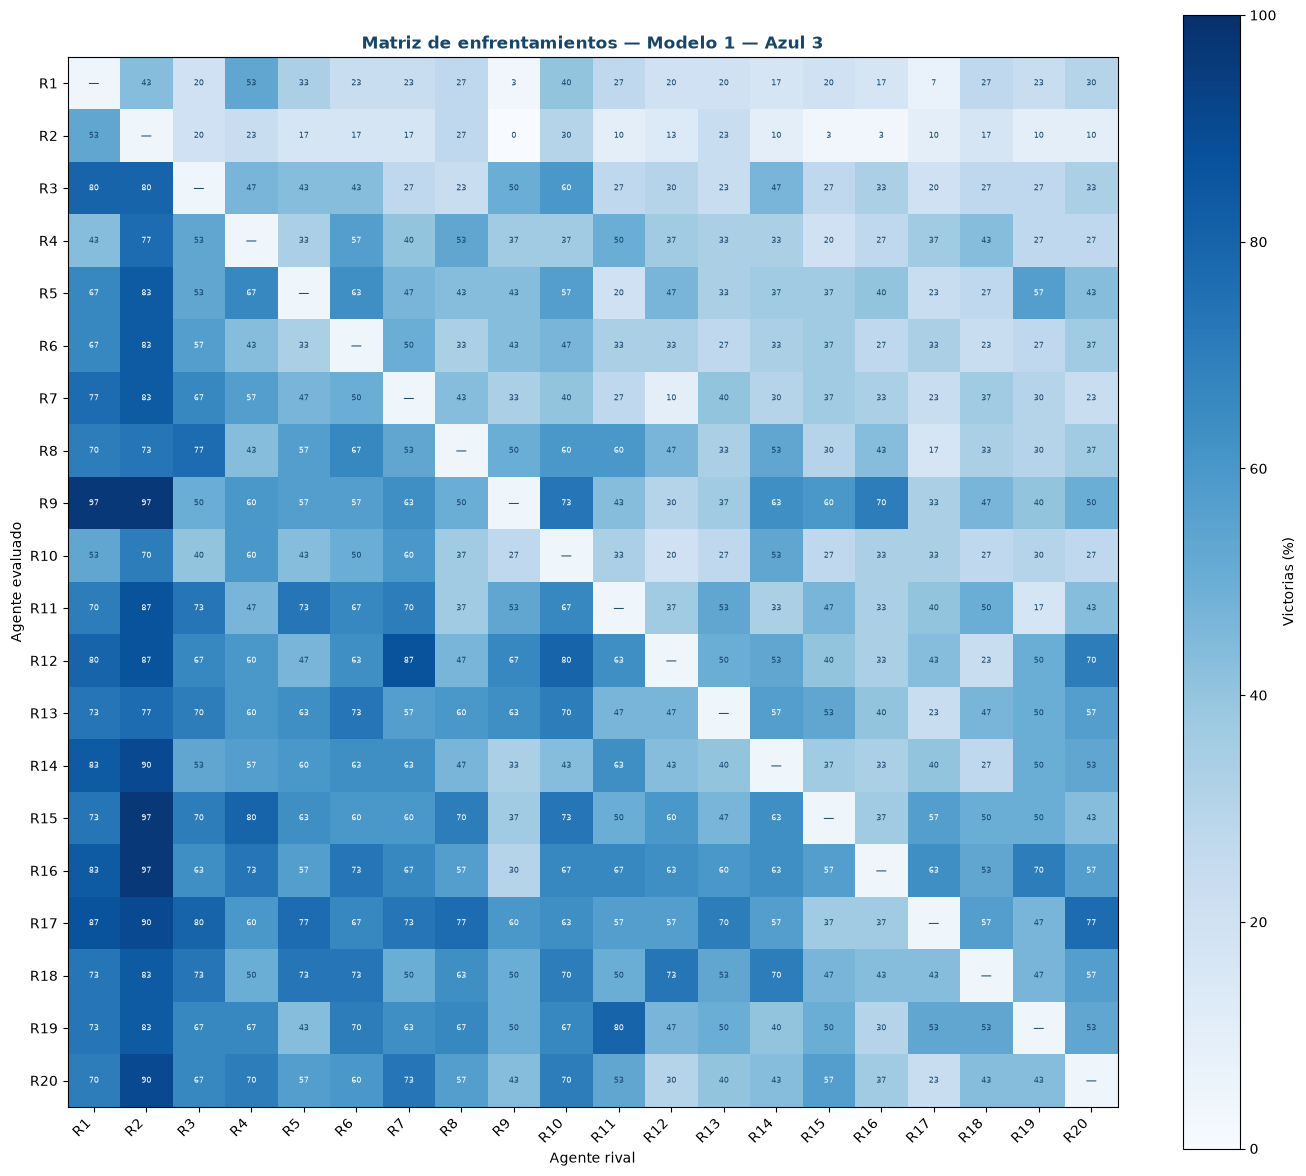

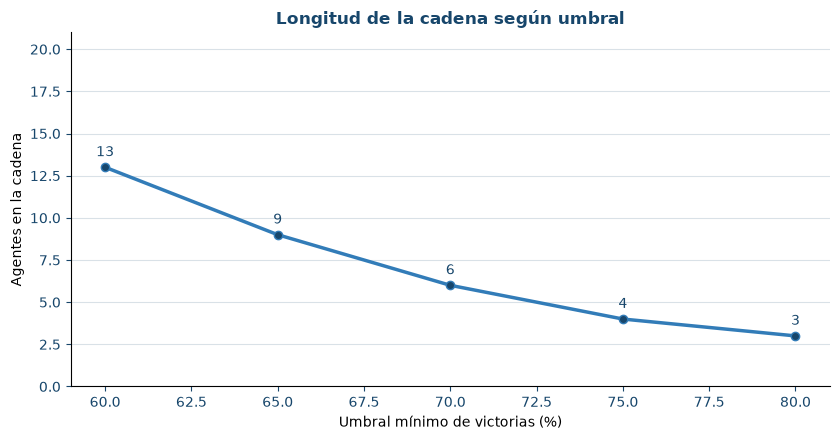

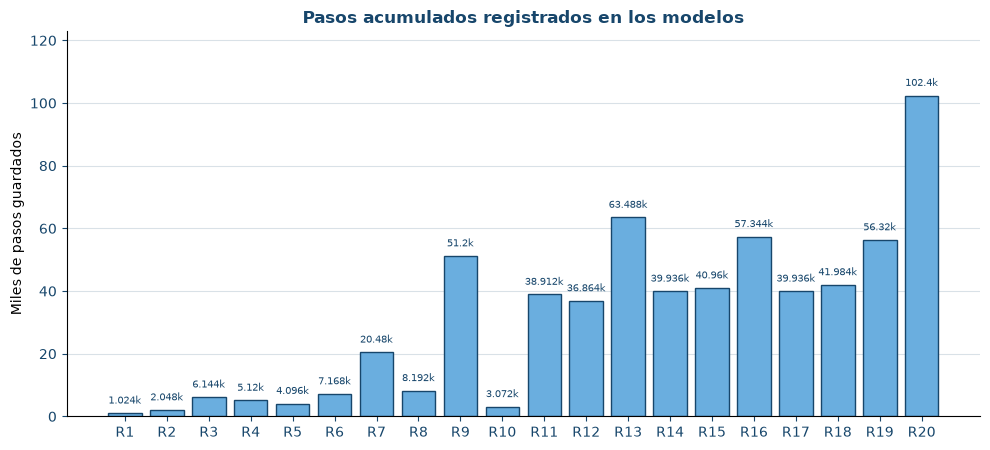

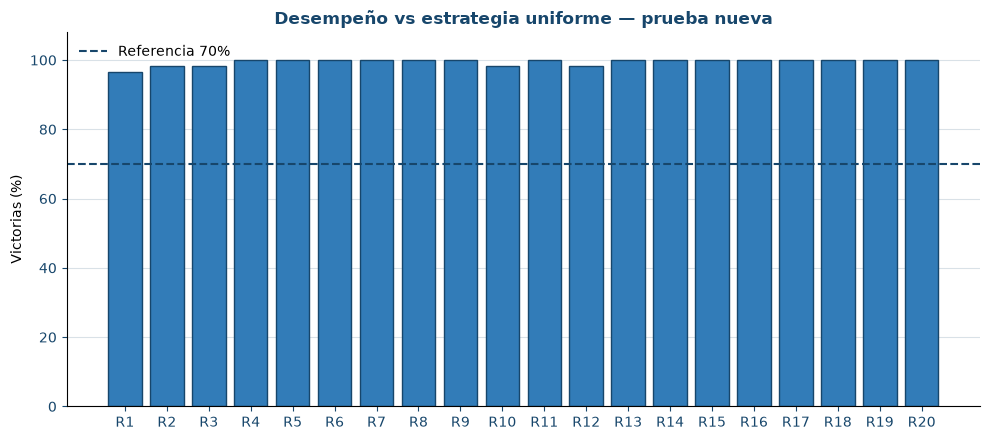

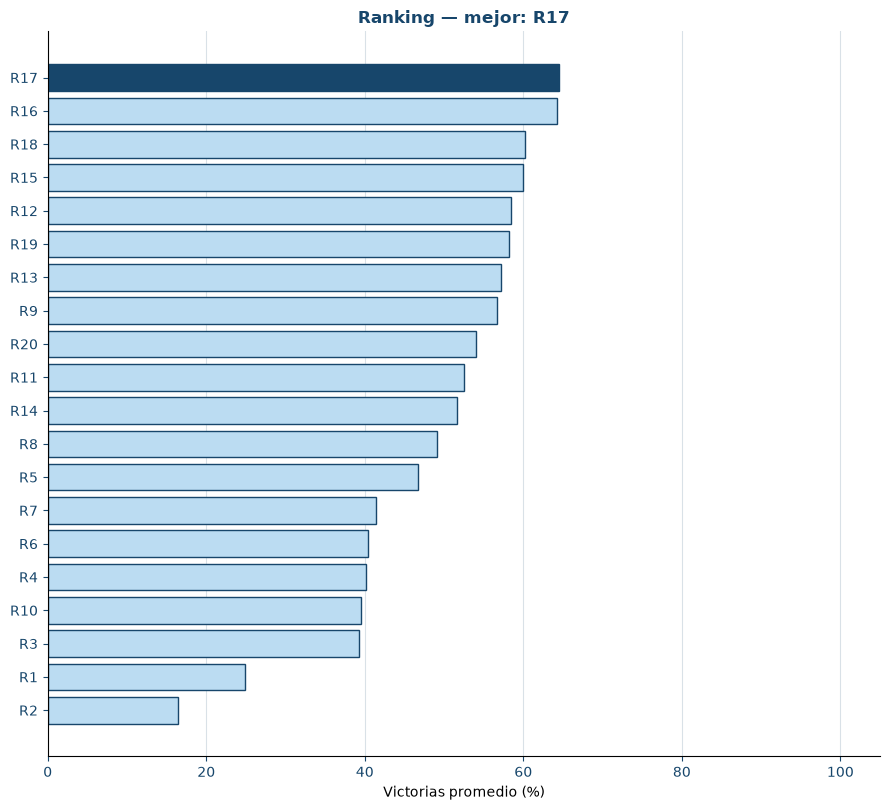

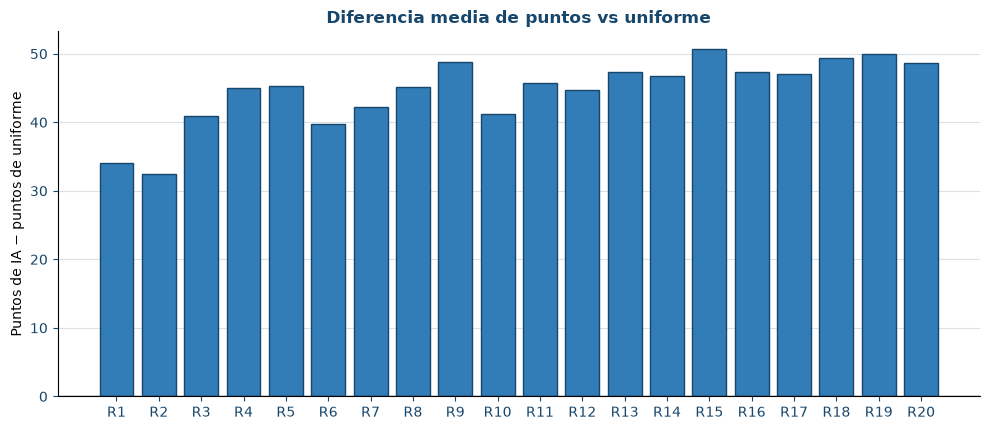

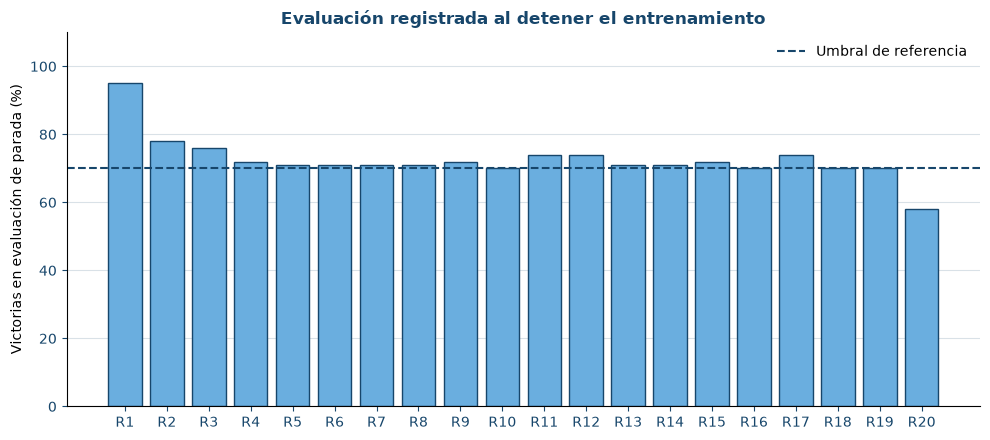


MEJOR DE Modelo 1 — Azul 3: R17
Victorias promedio vs los demás del mismo grupo: 64.56%
Figuras y tablas en: C:\Users\maria\Desktop\simula\azulfinal\salidas_sin_entrenamiento\modelo_1


,Agente,Victorias promedio vs otros (%),Victorias vs uniforme (%),Puntos medios vs uniforme,Pasos acumulados
0,R17,64.56,100.00,47.07,39936
1,R16,64.21,100.00,47.32,57344
2,R18,60.18,100.00,49.35,41984
3,R15,60.00,100.00,50.73,40960
4,R12,58.42,98.33,44.65,36864
5,R19,58.25,100.00,49.93,56320
6,R13,57.19,100.00,47.37,63488
7,R9,56.67,100.00,48.73,51200
8,R20,54.04,100.00,48.65,102400
9,R11,52.46,100.00,45.78,38912


In [8]:
resultado_modelo_1 = evaluar_conjunto("modelo_1")


## MODELO 2 


Modelo 2 — 1 a 1 — 10 agentes: 45 parejas con 30 partidas/pareja.
  Parejas evaluadas: 10/45
  Parejas evaluadas: 20/45
  Parejas evaluadas: 30/45
  Parejas evaluadas: 40/45
  Parejas evaluadas: 45/45
  R1 vs uniforme: 96.7%  (0 empates)
  R2 vs uniforme: 100.0%  (0 empates)
  R3 vs uniforme: 98.3%  (1 empates)
  R4 vs uniforme: 100.0%  (0 empates)
  R5 vs uniforme: 100.0%  (0 empates)
  R6 vs uniforme: 100.0%  (0 empates)
  R7 vs uniforme: 100.0%  (0 empates)
  R8 vs uniforme: 100.0%  (0 empates)
  R9 vs uniforme: 100.0%  (0 empates)
  R10 vs uniforme: 100.0%  (0 empates)
  Cadena >= 60%: 8 agentes; exacta
  Cadena >= 65%: 4 agentes; exacta
  Cadena >= 70%: 4 agentes; exacta
  Cadena >= 75%: 3 agentes; exacta
  Cadena >= 80%: 3 agentes; exacta


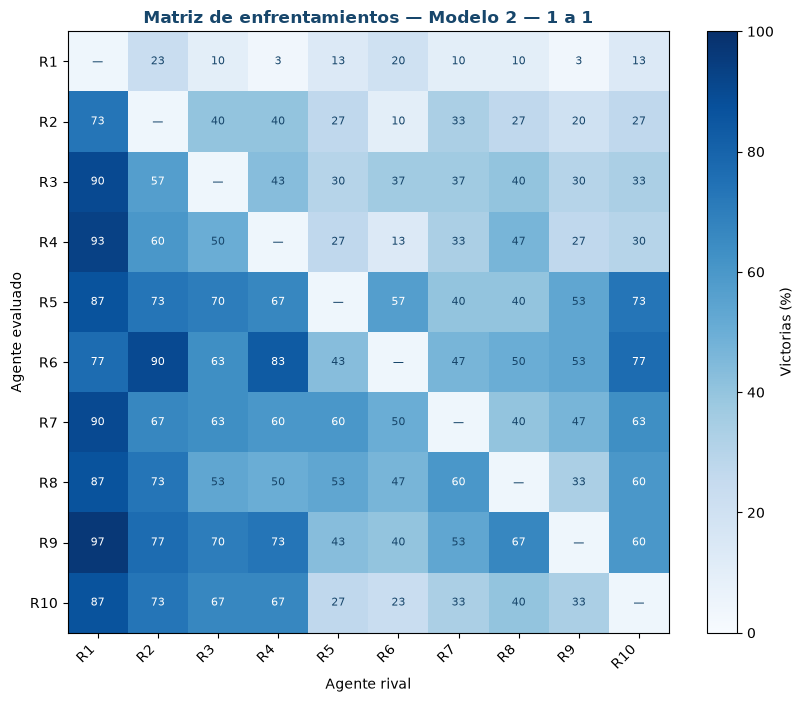

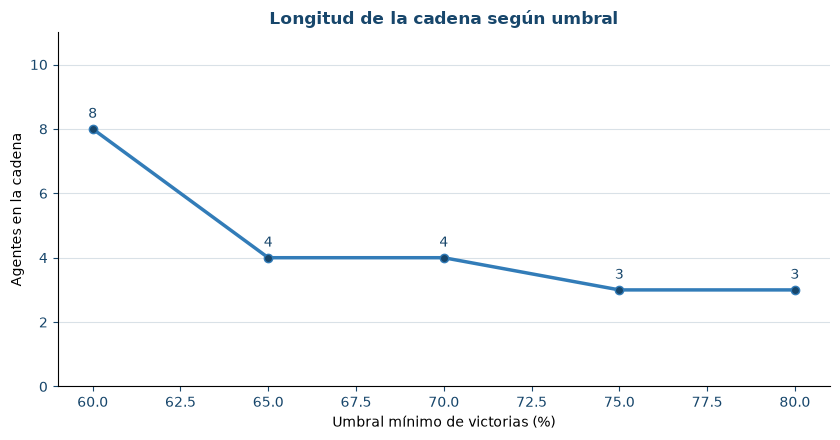

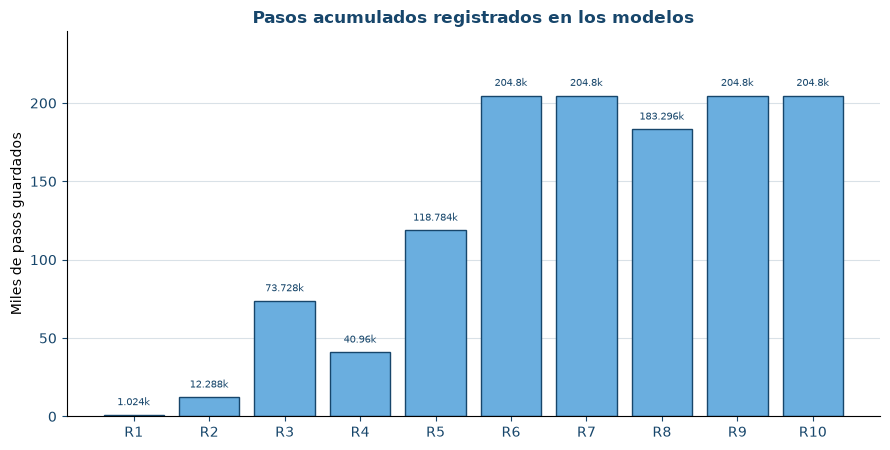

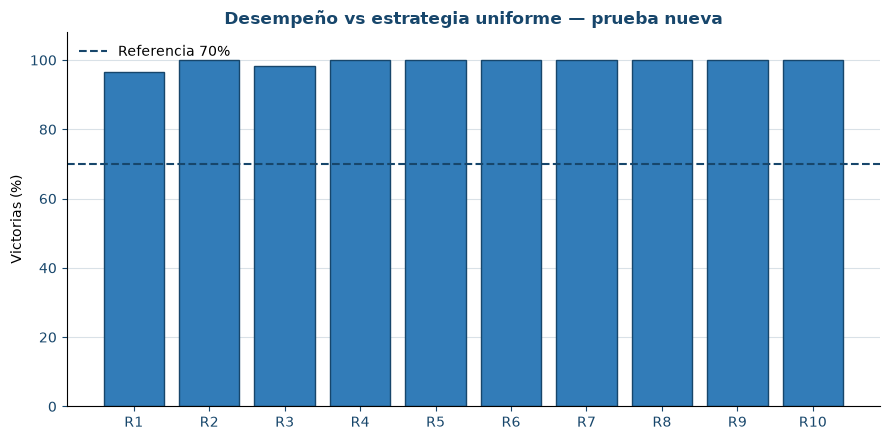

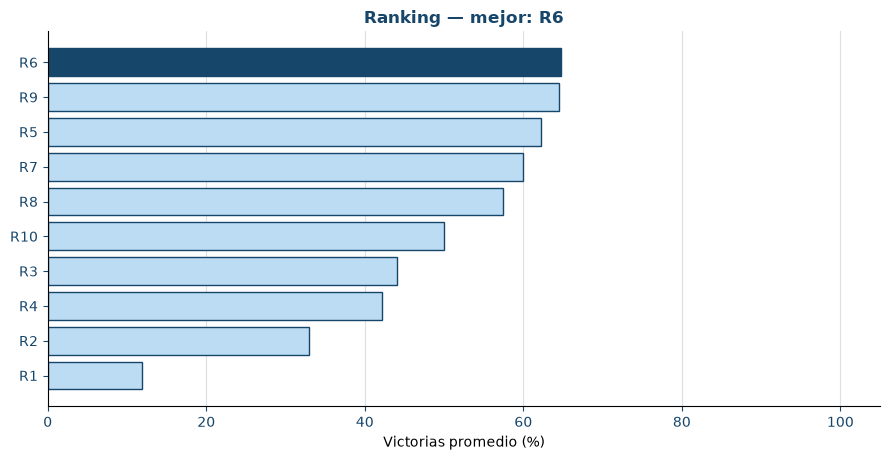

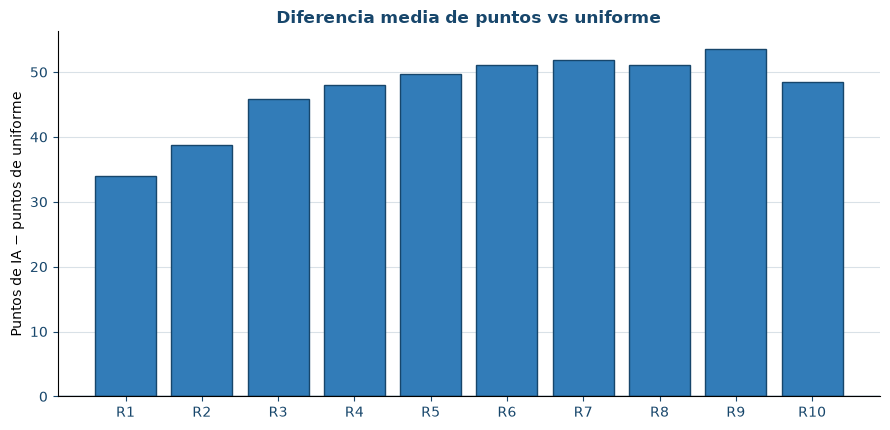

Modelo 2 — 1 a 1: sin historial de parada; NO se inventa tasas_parada.png

MEJOR DE Modelo 2 — 1 a 1: R6
Victorias promedio vs los demás del mismo grupo: 64.81%
Figuras y tablas en: C:\Users\maria\Desktop\simula\azulfinal\salidas_sin_entrenamiento\modelo_2


,Agente,Victorias promedio vs otros (%),Victorias vs uniforme (%),Puntos medios vs uniforme,Pasos acumulados
0,R6,64.81,100.00,51.17,204800
1,R9,64.44,100.00,53.60,204800
2,R5,62.22,100.00,49.67,118784
3,R7,60.00,100.00,51.82,204800
4,R8,57.41,100.00,51.07,183296
5,R10,50.00,100.00,48.42,204800
6,R3,44.07,98.33,45.82,73728
7,R4,42.22,100.00,47.93,40960
8,R2,32.96,100.00,38.82,12288
9,R1,11.85,96.67,34.03,1024


In [9]:
resultado_modelo_2 = evaluar_conjunto("modelo_2")


## MODELO 3 


Modelo 3 — Heurística — 9 agentes: 36 parejas con 30 partidas/pareja.
  Parejas evaluadas: 10/36
  Parejas evaluadas: 20/36
  Parejas evaluadas: 30/36
  Parejas evaluadas: 36/36
  R1 vs uniforme: 96.7%  (0 empates)
  R2 vs uniforme: 98.3%  (0 empates)
  R3 vs uniforme: 100.0%  (0 empates)
  R4 vs uniforme: 100.0%  (0 empates)
  R5 vs uniforme: 100.0%  (0 empates)
  R6 vs uniforme: 96.7%  (0 empates)
  R7 vs uniforme: 100.0%  (0 empates)
  R8 vs uniforme: 100.0%  (0 empates)
  R9 vs uniforme: 100.0%  (0 empates)
  Cadena >= 60%: 6 agentes; exacta
  Cadena >= 65%: 3 agentes; exacta
  Cadena >= 70%: 2 agentes; exacta
  Cadena >= 75%: 2 agentes; exacta
  Cadena >= 80%: 1 agentes; exacta


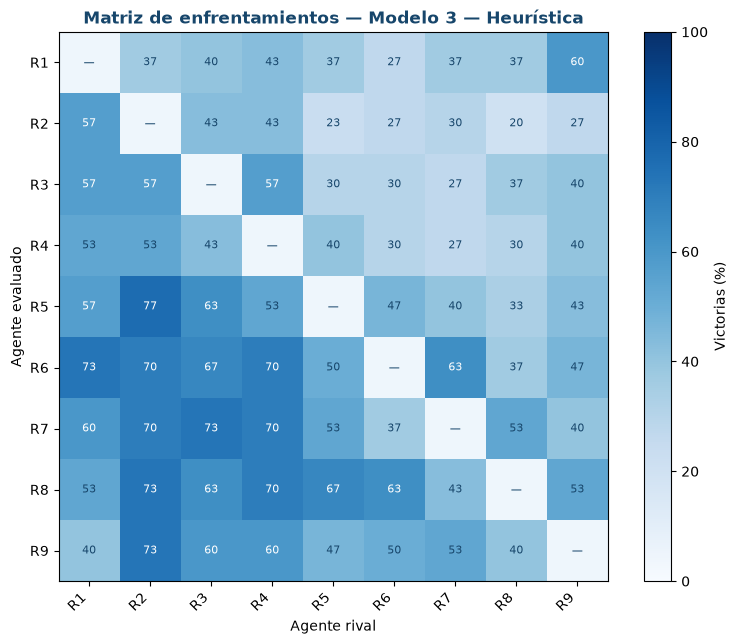

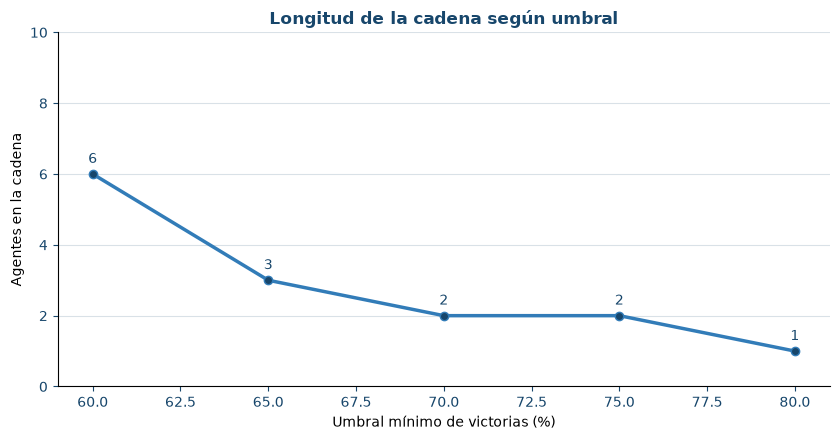

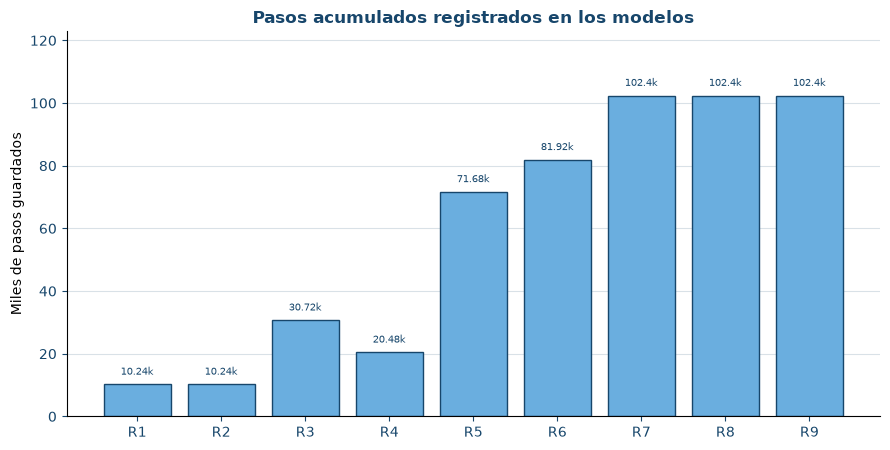

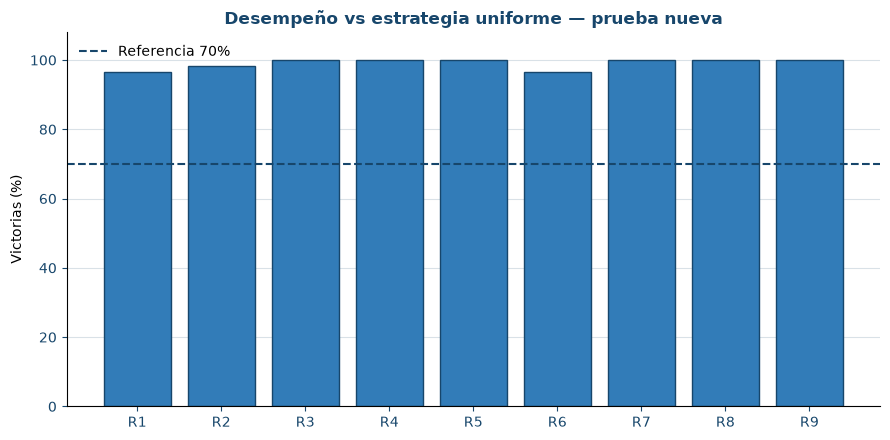

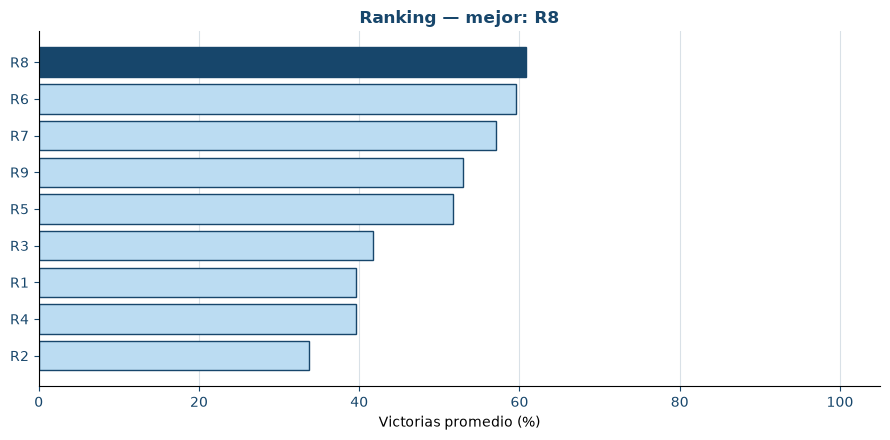

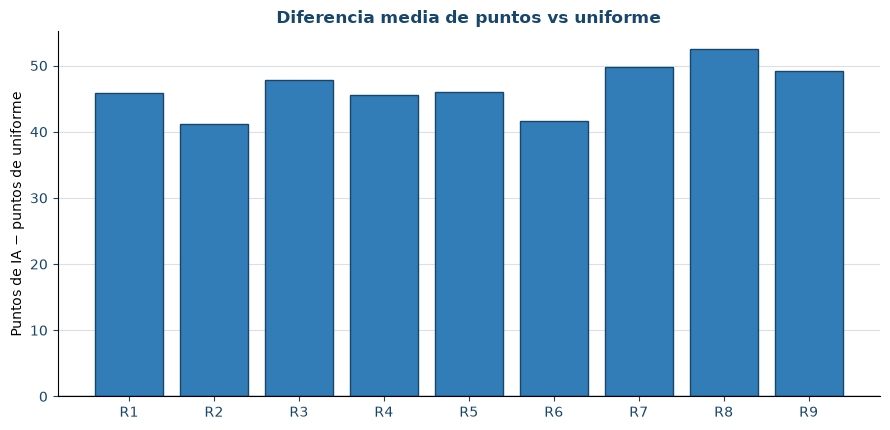

Modelo 3 — Heurística: sin historial de parada; NO se inventa tasas_parada.png

MEJOR DE Modelo 3 — Heurística: R8
Victorias promedio vs los demás del mismo grupo: 60.83%
Figuras y tablas en: C:\Users\maria\Desktop\simula\azulfinal\salidas_sin_entrenamiento\modelo_3


,Agente,Victorias promedio vs otros (%),Victorias vs uniforme (%),Puntos medios vs uniforme,Pasos acumulados
0,R8,60.83,100.00,52.55,102400
1,R6,59.58,96.67,41.58,81920
2,R7,57.08,100.00,49.73,102400
3,R9,52.92,100.00,49.18,102400
4,R5,51.67,100.00,46.02,71680
5,R3,41.67,100.00,47.85,30720
6,R4,39.58,100.00,45.57,20480
7,R1,39.58,96.67,45.90,10240
8,R2,33.75,98.33,41.18,10240


In [10]:
resultado_modelo_3 = evaluar_conjunto("modelo_3")

,Conjunto,Mejor agente,Victorias vs uniforme (%),Mejora vs Modelo 1 (pp),Puntos medios vs uniforme,Promedio victorias vs campeones rivales (%),Pasos guardados
0,Modelo 1 — Azul 3,R17,100.0,0.0,47.38,40.00,39936
1,Modelo 2 — 1 a 1,R6,100.0,0.0,50.90,61.67,204800
2,Modelo 3 — Heurística,R8,100.0,0.0,48.83,43.75,102400



MEJOR CAMPEÓN SEGÚN LOS DUELOS DIRECTOS: Modelo 2: R6
Promedio de victorias ante los otros dos campeones: 61.67%

Nota: comparación basada en los campeones; NO equivale a un torneo de todos contra todos entre los 39 agentes.


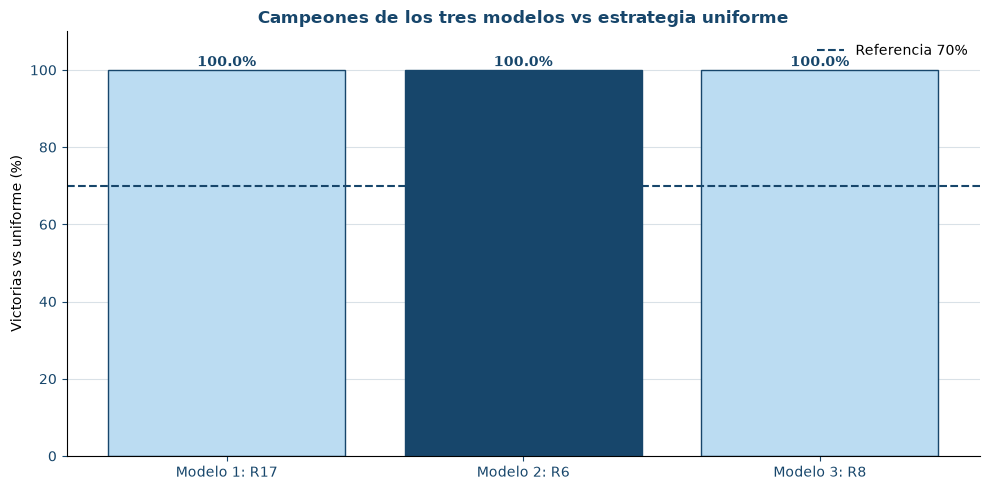

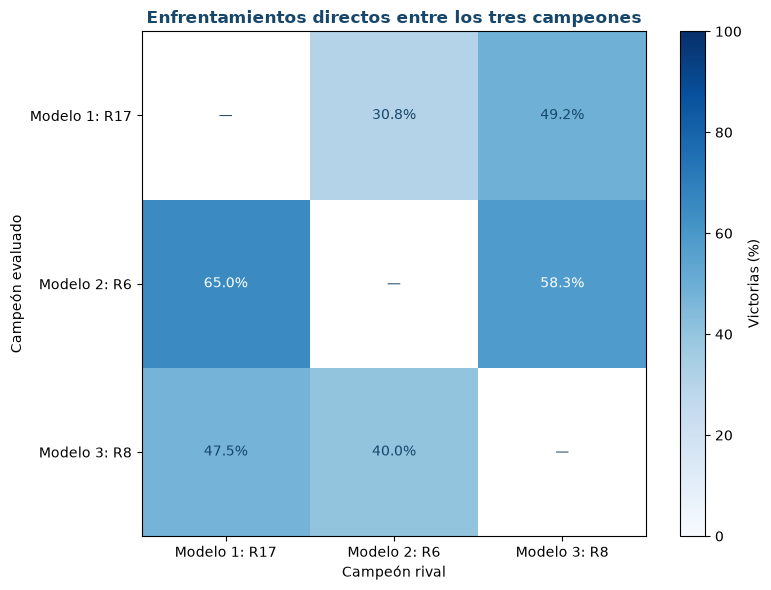

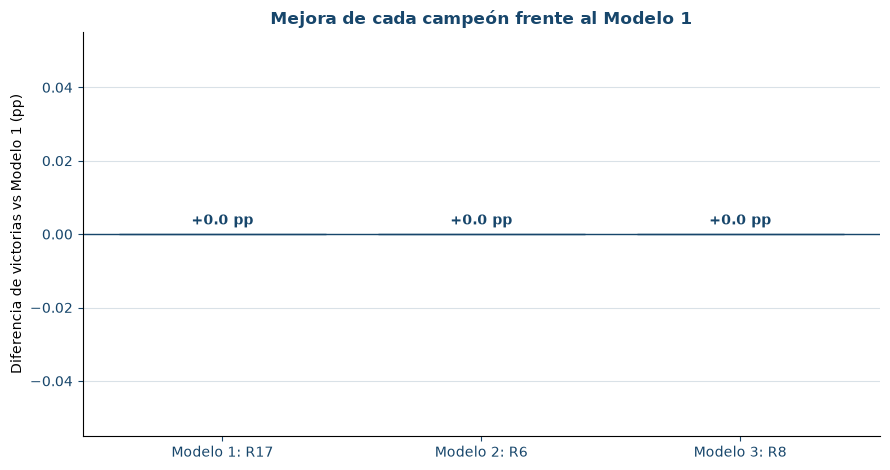


Comparación final guardada en: C:\Users\maria\Desktop\simula\azulfinal\salidas_sin_entrenamiento


In [ ]:
#hecho con ia
GRUPOS_ORDEN = ["modelo_1", "modelo_2", "modelo_3"]
if any(g not in ESTADISTICAS for g in GRUPOS_ORDEN):
    raise RuntimeError("Ejecuta primero las evaluaciones de Modelo 1, Modelo 2 y Modelo 3.")

campeones = [(g, ESTADISTICAS[g]["mejor"]) for g in GRUPOS_ORDEN]
etiquetas=[f"Modelo {k+1}: R{numero}" for k, (_, numero) in enumerate(campeones)]
C=np.full((3,3),np.nan)
D=np.full((3,3),np.nan)
cruces=[]
cache=BASE_SALIDAS/"cache_cruce_campeones.json"
for a in range(3):
    for b in range(a+1,3):
        ga,ia=campeones[a]
        gb,ib=campeones[b]
        r=duelo_cache(cache,MODELOS[ga][ia],MODELOS[gb][ib],HUELLAS[ga][ia],HUELLAS[gb][ib],
                     PARTIDAS_CRUCE_CAMPEONES,SEMILLA_CRUCES,
                     f"{ga}/R{ia}",f"{gb}/R{ib}")
        C[a,b]=r["winrate_a"]
        C[b,a]=r["winrate_b"]
        D[a,b]=r["diferencia_media"]
        D[b,a]=-r["diferencia_media"]
        cruces.append({"campeon_a":etiquetas[a],"campeon_b":etiquetas[b],
                        "partidas":r["partidas"],"victorias_a_pct":r["winrate_a"]*100,
                        "victorias_b_pct":r["winrate_b"]*100,"empates":r["empates"],
                        "diferencia_puntos_a":r["diferencia_media"]})

# Evaluación de los tres campeones contra la misma uniforme (semillas compartidas).
cache_uni=BASE_SALIDAS/"cache_campeones_uniforme.json"
uni_campeones=[]
for g,i in campeones:
    r=duelo_cache(cache_uni,MODELOS[g][i],None,HUELLAS[g][i],"uniforme",
                 PARTIDAS_CRUCE_CAMPEONES,SEMILLA_CRUCES+100000,f"{g}/R{i}","uniforme")
    uni_campeones.append(r)

prom_cruces=np.nanmean(C,axis=1)
orden=np.argsort(-prom_cruces)
mejor_global=int(orden[0])
BASE=uni_campeones[0]["winrate_a"]*100
comparacion=pd.DataFrame({
    "Conjunto":[CONJUNTOS[g]["nombre"] for g,_ in campeones],
    "Mejor agente":[f"R{i}" for _,i in campeones],
    "Victorias vs uniforme (%)":[round(r["winrate_a"]*100,2) for r in uni_campeones],
    "Mejora vs Modelo 1 (pp)":[round(r["winrate_a"]*100-BASE,2) for r in uni_campeones],
    "Puntos medios vs uniforme":[round(r["diferencia_media"],2) for r in uni_campeones],
    "Promedio victorias vs campeones rivales (%)":np.round(prom_cruces*100,2),
    "Pasos guardados":[int(getattr(MODELOS[g][i],"num_timesteps",0)) for g,i in campeones]
})

comparacion.to_csv(BASE_SALIDAS/"comparacion_tres_modelos.csv",index=False,encoding="utf-8-sig")
pd.DataFrame(C*100,index=etiquetas,columns=etiquetas).to_csv(BASE_SALIDAS/"matriz_campeones.csv",encoding="utf-8-sig")
pd.DataFrame(cruces).to_csv(BASE_SALIDAS/"duelos_campeones.csv",index=False,encoding="utf-8-sig")

display(comparacion)
print("\nMEJOR CAMPEÓN SEGÚN LOS DUELOS DIRECTOS:", etiquetas[mejor_global])
print(f"Promedio de victorias ante los otros dos campeones: {prom_cruces[mejor_global]*100:.2f}%")
print("\nNota: comparación basada en los campeones; NO equivale a un torneo de todos contra todos entre los 39 agentes.")

# Gráfico: los tres campeones contra uniforme.
fig,ax=plt.subplots(figsize=(10,5))
colores=[PALETA["oscuro"] if k==mejor_global else PALETA["claro"] for k in range(3)]
bs=ax.bar(etiquetas,comparacion["Victorias vs uniforme (%)"],color=colores,edgecolor=PALETA["oscuro"])
for bar,v in zip(bs,comparacion["Victorias vs uniforme (%)"]):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+1,f"{v:.1f}%",ha="center",color=PALETA["oscuro"],fontweight="bold")
ax.axhline(UMBRAL_REFERENCIA,color=PALETA["oscuro"],ls="--",label=f"Referencia {UMBRAL_REFERENCIA}%")
ax.set_ylim(0,110);ax.set_ylabel("Victorias vs uniforme (%)")
ax.set_title("Campeones de los tres modelos vs estrategia uniforme",color=PALETA["oscuro"],fontweight="bold")
ax.legend(frameon=False);estilo(ax);guardar_fig(fig, BASE_SALIDAS/"comparacion_uniforme.png")

# Gráfico: matriz entre campeones de tres conjuntos.
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(np.ma.masked_invalid(C*100),cmap="Blues",vmin=0,vmax=100)
ax.set_xticks(range(3),etiquetas);ax.set_yticks(range(3),etiquetas)
ax.set_xlabel("Campeón rival");ax.set_ylabel("Campeón evaluado")
ax.set_title("Enfrentamientos directos entre los tres campeones",color=PALETA["oscuro"],fontweight="bold")
for i in range(3):
    for j in range(3):
        texto="—" if i==j else f"{100*C[i,j]:.1f}%"
        ax.text(j,i,texto,ha="center",va="center",color=("white" if i!=j and C[i,j]>=.55 else PALETA["oscuro"]))
fig.colorbar(im,ax=ax,label="Victorias (%)")
guardar_fig(fig,BASE_SALIDAS/"matriz_campeones.png")

# Gráfico: diferencias respecto al campeón del Modelo 1.
fig,ax=plt.subplots(figsize=(9,4.8))
mejoras=comparacion["Mejora vs Modelo 1 (pp)"].to_numpy(dtype=float)
bs=ax.bar(etiquetas,mejoras,color=[PALETA["azul"] if v>=0 else PALETA["claro"] for v in mejoras],edgecolor=PALETA["oscuro"])
ax.axhline(0,color=PALETA["oscuro"],linewidth=1)
for bar,v in zip(bs,mejoras):
    ax.annotate(f"{v:+.1f} pp",(bar.get_x()+bar.get_width()/2,v),xytext=(0,7 if v>=0 else -16),textcoords="offset points",ha="center",color=PALETA["oscuro"],fontweight="bold")
ax.set_ylabel("Diferencia de victorias vs Modelo 1 (pp)")
ax.set_title("Mejora de cada campeón frente al Modelo 1",color=PALETA["oscuro"],fontweight="bold")
estilo(ax);guardar_fig(fig,BASE_SALIDAS/"mejora_respecto_modelo_1.png")
print("\nComparación final guardada en:",BASE_SALIDAS.resolve())
#hecho con ia

In [12]:
GENERAR_VIDEOS = False   # Cambia a True si quieres generar 3 MP4.
FPS_MP4 = 2
SEMILLA_VIDEO = 2026

if GENERAR_VIDEOS:
    from unittest.mock import patch
    import imageio.v2 as imageio
    from PIL import Image
    from IPython.display import clear_output

    def video_mejor_vs_uniforme(grupo, numero, semilla=SEMILLA_VIDEO):
        modelo=MODELOS[grupo][numero]
        partida=nueva_partida(semilla)
        partida.jugadores[0].nombre=f"IA R{numero}"
        partida.jugadores[1].nombre="Uniforme"
        rng=np.random.default_rng(semilla+99999)
        ruta=salida_grupo(grupo)/f"video_R{numero}_vs_uniforme.mp4"
        historial=[]
        def escribir_frame(writer, texto):
            with patch.object(plt,"show",lambda *args,**kwargs:None):
                partida.mostrar_estado()
            fig=plt.gcf()
            fig.text(.5,.015,texto,ha="center",fontsize=10,fontweight="bold",color=PALETA["oscuro"])
            fig.canvas.draw()
            imagen=np.asarray(fig.canvas.buffer_rgba()).copy()[:,:,:3]
            # Dimensiones múltiplos de 16 para codificación H.264
            imagen=np.asarray(Image.fromarray(imagen).resize((1120,720)))
            writer.append_data(imagen)
            plt.close(fig)
        with imageio.get_writer(str(ruta),fps=FPS_MP4,codec="libx264",quality=7) as writer:
            escribir_frame(writer,f"Inicio: R{numero} contra uniforme")
            for turno in range(1,MAX_TURNOS+1):
                if partida.terminada:
                    break
                j=partida.turno
                if j==0:
                    jugada=accion_modelo(modelo,partida,j)
                    actor=f"IA R{numero}"
                else:
                    jugada=jugada_uniforme(partida,rng)
                    actor="Uniforme"
                ronda=partida.azul.ronda
                _jugar_sin_imprimir(partida,jugada)
                historial.append({"turno":turno,"ronda":ronda,"actor":actor,"jugada":str(jugada),
                                  "puntos_IA":int(partida.jugadores[0].puntos),
                                  "puntos_uniforme":int(partida.jugadores[1].puntos)})
                escribir_frame(writer,f"Turno {turno}: {actor} {jugada}; IA {historial[-1]['puntos_IA']} - Uniforme {historial[-1]['puntos_uniforme']}")
            if not partida.terminada:
                warnings.warn("La partida llegó al máximo de turnos sin terminar.")
            else:
                a,b=[int(j.puntos) for j in partida.jugadores]
                resultado="Gana IA" if a>b else "Gana uniforme" if b>a else "Empate"
                for _ in range(4):
                    escribir_frame(writer,f"FINAL: IA {a} - Uniforme {b} | {resultado}")
        pd.DataFrame(historial).to_csv(salida_grupo(grupo)/f"historial_video_R{numero}.csv",index=False,encoding="utf-8-sig")
        print("Video guardado:",ruta.resolve())

    for grupo in ["modelo_1","modelo_2","modelo_3"]:
        video_mejor_vs_uniforme(grupo,ESTADISTICAS[grupo]["mejor"])
else:
    print("Videos desactivados (opcional). Cambia GENERAR_VIDEOS=True si los necesitas.")

Videos desactivados (opcional). Cambia GENERAR_VIDEOS=True si los necesitas.


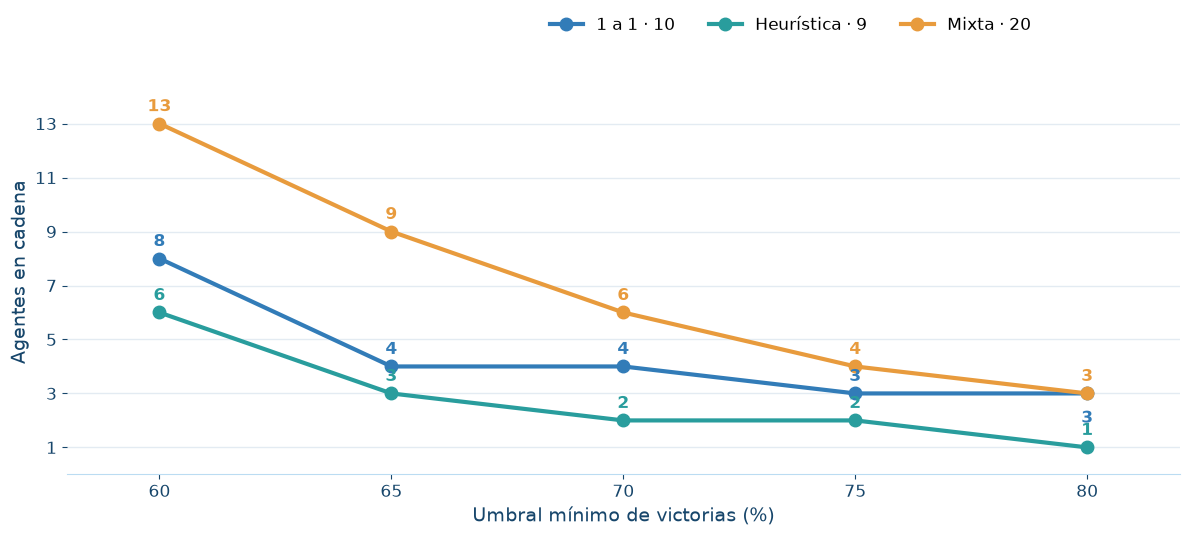

Gráfico guardado en: salidas_sin_entrenamiento\comparacion_largos_cadenas.png


In [14]:
#hecho con ia
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path("salidas_sin_entrenamiento")

conjuntos = [
    ("modelo_2", "1 a 1 · 10", "#327CB8"),
    ("modelo_3", "Heurística · 9", "#299D9D"),
    ("modelo_1", "Mixta · 20", "#E89B3D")
]

umbrales = [60, 65, 70, 75, 80]
fig, ax = plt.subplots(figsize=(12, 5.5))
for grupo, nombre, color in conjuntos:

    if "ESTADISTICAS" in globals() and grupo in ESTADISTICAS:
        cadenas = ESTADISTICAS[grupo]["cadenas"]
    else:
        with open(base / grupo / "cadenas.json",
                  "r", encoding="utf-8") as f:
            cadenas = json.load(f)

    datos = {
        int(c["umbral_pct"]): int(c["longitud"])
        for c in cadenas
    }

    largos = [datos[u] for u in umbrales]

    ax.plot(
        umbrales,
        largos,
        marker="o",
        markersize=9,
        linewidth=3,
        color=color,
        label=nombre
    )

    # Etiquetas sobre cada punto
    for x, y in zip(umbrales, largos):

        desplazamiento = 9

        # Evitar que se superpongan los números
        if grupo == "modelo_2" and x == 80:
            desplazamiento = -21

        ax.annotate(
            str(y),
            (x, y),
            xytext=(0, desplazamiento),
            textcoords="offset points",
            ha="center",
            fontsize=12,
            fontweight="bold",
            color=color
        )


ax.set_xlabel(
    "Umbral mínimo de victorias (%)",
    fontsize=14,
    color="#17466B"
)

ax.set_ylabel(
    "Agentes en cadena",
    fontsize=14,
    color="#17466B"
)

ax.set_xticks(umbrales)
ax.set_xlim(58, 82)
ax.set_ylim(0, 15)
ax.set_yticks(np.arange(1, 14, 2))

ax.tick_params(
    axis="both",
    labelsize=12,
    colors="#17466B"
)

ax.grid(
    axis="y",
    color="#DCE6EF",
    linewidth=1,
    alpha=0.8
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#BBDCF2")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.65, 1.17),
    ncol=3,
    frameon=False,
    fontsize=12
)

plt.tight_layout()

#hecho con ia

ruta = base / "comparacion_largos_cadenas.png"

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Gráfico guardado en: {ruta}")
#hecho con ia